In [1]:
#数据导入 → 提取变量 → 检查原始编码

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Output folder
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Output directory:", output_dir.resolve())

Output directory: C:\Users\20496\Desktop\ESS10_analysis\outputs


In [4]:
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10
})

def format_plot(ax, title, xlabel, ylabel):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()

In [5]:
df = pd.read_csv("ESS10e03_3.csv", low_memory=False)

In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (37611, 621)


In [7]:
variables = [
    "idno",
    "cntry",
    "anweight",

    "stflife",
    "wkhtot",
    "health",
    "sclact",
    "netustm",
    "ppltrst",
    "aesfdrk",
    "hinctnta",
    "gndr",
    "agea",
    "maritalb",
    "rlgblg",
    "edulvlb",
    "tporgwk",
    "happy"
]

ess10 = df[variables].copy()

In [8]:
print(ess10.shape)
ess10.head()

(37611, 18)


,idno,cntry,anweight,stflife,wkhtot,health,sclact,netustm,ppltrst,aesfdrk,hinctnta,gndr,agea,maritalb,rlgblg,edulvlb,tporgwk,happy
0,10038,BE,0.698167,7,666,2,2,8,6,2,88,2,16,6,1,113,66,7
1,10053,BE,0.638107,7,40,2,2,240,3,2,88,2,24,6,2,720,4,6
2,10055,BE,0.519033,8,42,2,1,120,6,1,7,1,58,1,2,610,4,8
3,10062,BE,0.722072,10,35,1,2,90,7,2,7,1,35,4,1,323,6,10
4,10064,BE,0.458639,9,40,1,2,120,3,1,6,1,61,6,2,800,2,7


In [9]:
for var in variables[3:]:
    print("\n", "=" * 50)
    print(var)
    print(ess10[var].value_counts(dropna=False).sort_index())


stflife
stflife
0      447
1      241
2      684
3     1230
4     1440
5     3967
6     3646
7     7052
8     9224
9     5319
10    4005
77     129
88     188
99      39
Name: count, dtype: int64

wkhtot
wkhtot
0       618
1        32
2        71
3        48
4        78
       ... 
168      99
666    4134
777     619
888    2029
999     234
Name: count, Length: 116, dtype: int64

health
health
1     9814
2    15732
3     9247
4     2357
5      417
7       16
8       18
9       10
Name: count, dtype: int64

sclact
sclact
1     4122
2     9774
3    17628
4     4537
5      952
7       49
8      489
9       60
Name: count, dtype: int64

netustm
netustm
0         43
1          7
2          7
3          1
5         21
        ... 
1440       7
6666    9472
7777      20
8888     495
9999      26
Name: count, Length: 226, dtype: int64

ppltrst
ppltrst
0     2753
1     1391
2     2610
3     3849
4     3602
5     6840
6     4255
7     5697
8     4426
9     1249
10     818
77      31
88      76


In [10]:
#缺失值清洗 + 按论文重编码

In [11]:
clean = ess10.copy()

print("Original sample size:", len(clean))

Original sample size: 37611


In [12]:
# Life satisfaction
clean["stflife"] = clean["stflife"].replace(
    [77, 88, 99], np.nan
)

# Weekly working hours
clean["wkhtot"] = clean["wkhtot"].replace(
    [666, 777, 888, 999], np.nan
)

# General health
clean["health"] = clean["health"].replace(
    [7, 8, 9], np.nan
)

# Social inclusion
clean["sclact"] = clean["sclact"].replace(
    [7, 8, 9], np.nan
)

# Internet use time
clean["netustm"] = clean["netustm"].replace(
    [6666, 7777, 8888, 9999], np.nan
)

# Social trust
clean["ppltrst"] = clean["ppltrst"].replace(
    [77, 88, 99], np.nan
)

# Safety
clean["aesfdrk"] = clean["aesfdrk"].replace(
    [7, 8, 9], np.nan
)

# Household income
clean["hinctnta"] = clean["hinctnta"].replace(
    [77, 88, 99], np.nan
)

# Age
clean["agea"] = clean["agea"].replace(
    [999], np.nan
)

# Marital status
clean["maritalb"] = clean["maritalb"].replace(
    [77, 88, 99], np.nan
)

# Religion
clean["rlgblg"] = clean["rlgblg"].replace(
    [7, 8, 9], np.nan
)

# Education
clean["edulvlb"] = clean["edulvlb"].replace(
    [5555, 7777, 8888, 9999], np.nan
)

# Type of organisation
clean["tporgwk"] = clean["tporgwk"].replace(
    [66, 77, 88, 99], np.nan
)

# Happiness
clean["happy"] = clean["happy"].replace(
    [77, 88, 99], np.nan
)

In [13]:
#Step 5.3 检查特殊编码有没有真的清掉

In [14]:
clean[
    [
        "stflife", "wkhtot", "health", "sclact",
        "netustm", "ppltrst", "aesfdrk",
        "hinctnta", "gndr", "agea",
        "maritalb", "rlgblg", "edulvlb",
        "tporgwk", "happy"
    ]
].isna().sum()

stflife       356
wkhtot       7016
health         44
sclact        598
netustm     10013
ppltrst       121
aesfdrk       312
hinctnta     8239
gndr            0
agea          292
maritalb      344
rlgblg        302
edulvlb       242
tporgwk      4766
happy          90
dtype: int64

In [15]:
#Step 5.4 按论文重新建立分析变量

In [16]:
clean["life_satisfaction"] = clean["stflife"]

In [17]:
clean["worktime"] = clean["wkhtot"]

In [18]:
clean["worktime"].describe()

count    30595.000000
mean        40.046217
std         15.906511
min          0.000000
25%         38.000000
50%         40.000000
75%         45.000000
max        168.000000
Name: worktime, dtype: float64

In [19]:
clean["health_clean"] = 6 - clean["health"]

In [20]:
clean[["health", "health_clean"]].drop_duplicates().sort_values("health")

,health,health_clean
3,1.0,5.0
0,2.0,4.0
9,3.0,3.0
6,4.0,2.0
154,5.0,1.0
3577,NaN,NaN


In [21]:
clean["income"] = clean["hinctnta"]

In [22]:
clean["gender"] = clean["gndr"].map({
    1: 1,
    2: 0
})

In [23]:
pd.crosstab(clean["gndr"], clean["gender"])

gender,0,1
gndr,,
1,0,17462
2,20149,0


In [24]:
clean["age"] = clean["agea"]

In [25]:
clean["married"] = clean["maritalb"].map({
    1: 1,
    2: 0,
    3: 0,
    4: 0,
    5: 0,
    6: 0
})

In [26]:
clean["religion"] = clean["rlgblg"].map({
    1: 1,
    2: 0
})

In [27]:
def recode_education(x):
    if pd.isna(x):
        return np.nan
    elif x <= 520:
        return 1
    elif x in [610, 620]:
        return 2
    elif x in [710, 720]:
        return 3
    elif x == 800:
        return 4
    else:
        return np.nan

clean["education"] = clean["edulvlb"].apply(recode_education)

In [28]:
clean["education"].value_counts(dropna=False).sort_index()

education
1.0    27410
2.0     4798
3.0     4770
4.0      391
NaN      242
Name: count, dtype: int64

In [29]:
clean["job_category"] = clean["tporgwk"]

In [30]:
clean["happiness"] = clean["happy"]

In [31]:
#Step 5.5 建立最终分析变量数据框

In [32]:
clean["social_inclusion"] = clean["sclact"]

clean["digitalization"] = clean["netustm"]

clean["trust"] = clean["ppltrst"]

clean["safety"] = 5 - clean["aesfdrk"]

In [33]:
clean[
    ["sclact", "social_inclusion",
     "netustm", "digitalization",
     "ppltrst", "trust",
     "aesfdrk", "safety"]
].head(10)

,sclact,social_inclusion,netustm,digitalization,ppltrst,trust,aesfdrk,safety
0,2.0,2.0,8.0,8.0,6.0,6.0,2.0,3.0
1,2.0,2.0,240.0,240.0,3.0,3.0,2.0,3.0
2,1.0,1.0,120.0,120.0,6.0,6.0,1.0,4.0
3,2.0,2.0,90.0,90.0,7.0,7.0,2.0,3.0
4,2.0,2.0,120.0,120.0,3.0,3.0,1.0,4.0
5,3.0,3.0,120.0,120.0,4.0,4.0,2.0,3.0
6,1.0,1.0,NaN,NaN,1.0,1.0,3.0,2.0
7,2.0,2.0,10.0,10.0,6.0,6.0,2.0,3.0
8,4.0,4.0,180.0,180.0,7.0,7.0,1.0,4.0
9,1.0,1.0,NaN,NaN,8.0,8.0,2.0,3.0


In [34]:
print(clean.columns.tolist())

['idno', 'cntry', 'anweight', 'stflife', 'wkhtot', 'health', 'sclact', 'netustm', 'ppltrst', 'aesfdrk', 'hinctnta', 'gndr', 'agea', 'maritalb', 'rlgblg', 'edulvlb', 'tporgwk', 'happy', 'life_satisfaction', 'worktime', 'health_clean', 'income', 'gender', 'age', 'married', 'religion', 'education', 'job_category', 'happiness', 'social_inclusion', 'digitalization', 'trust', 'safety']


In [35]:
# Step 5.5 Define variables for final analysis dataset

analysis_vars = [
    "idno",
    "cntry",
    "anweight",

    "life_satisfaction",
    "worktime",
    "health_clean",
    "social_inclusion",
    "digitalization",
    "trust",
    "safety",
    "income",
    "gender",
    "age",
    "married",
    "religion",
    "education",
    "job_category",
    "happiness"
]

print("Number of analysis variables:", len(analysis_vars))
print(analysis_vars)

Number of analysis variables: 18
['idno', 'cntry', 'anweight', 'life_satisfaction', 'worktime', 'health_clean', 'social_inclusion', 'digitalization', 'trust', 'safety', 'income', 'gender', 'age', 'married', 'religion', 'education', 'job_category', 'happiness']


In [36]:
analysis = clean[analysis_vars].copy()
analysis.head()

,idno,cntry,anweight,life_satisfaction,worktime,health_clean,social_inclusion,digitalization,trust,safety,income,gender,age,married,religion,education,job_category,happiness
0,10038,BE,0.698167,7.0,NaN,4.0,2.0,8.0,6.0,3.0,NaN,0,16.0,0.0,1.0,1.0,NaN,7.0
1,10053,BE,0.638107,7.0,40.0,4.0,2.0,240.0,3.0,3.0,NaN,0,24.0,0.0,0.0,3.0,4.0,6.0
2,10055,BE,0.519033,8.0,42.0,4.0,1.0,120.0,6.0,4.0,7.0,1,58.0,1.0,0.0,2.0,4.0,8.0
3,10062,BE,0.722072,10.0,35.0,5.0,2.0,90.0,7.0,3.0,7.0,1,35.0,0.0,1.0,1.0,6.0,10.0
4,10064,BE,0.458639,9.0,40.0,5.0,2.0,120.0,3.0,4.0,6.0,1,61.0,0.0,0.0,4.0,2.0,7.0


In [37]:
#Step 5.6：质量检查

In [38]:
analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37611 entries, 0 to 37610
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   idno               37611 non-null  int64  
 1   cntry              37611 non-null  object 
 2   anweight           37611 non-null  float64
 3   life_satisfaction  37255 non-null  float64
 4   worktime           30595 non-null  float64
 5   health_clean       37567 non-null  float64
 6   social_inclusion   37013 non-null  float64
 7   digitalization     27598 non-null  float64
 8   trust              37490 non-null  float64
 9   safety             37299 non-null  float64
 10  income             29372 non-null  float64
 11  gender             37611 non-null  int64  
 12  age                37319 non-null  float64
 13  married            37267 non-null  float64
 14  religion           37309 non-null  float64
 15  education          37369 non-null  float64
 16  job_category       328

In [39]:
analysis.isna().sum().sort_values(ascending=False)

digitalization       10013
income                8239
worktime              7016
job_category          4766
social_inclusion       598
life_satisfaction      356
married                344
safety                 312
religion               302
age                    292
education              242
trust                  121
happiness               90
health_clean            44
cntry                    0
idno                     0
anweight                 0
gender                   0
dtype: int64

In [40]:
analysis.describe().T

,count,mean,std,min,25%,50%,75%,max
idno,37611.0,30408.518758,21791.436583,10002.000000,15846.50000,21688.000000,27576.5000,93065.000000
anweight,37611.0,0.703150,1.228341,0.003017,0.13471,0.292922,0.6502,19.176882
life_satisfaction,37255.0,7.082190,2.111703,0.000000,6.00000,7.000000,9.0000,10.000000
worktime,30595.0,40.046217,15.906511,0.000000,38.00000,40.000000,45.0000,168.000000
health_clean,37567.0,3.856310,0.915221,1.000000,3.00000,4.000000,5.0000,5.000000
social_inclusion,37013.0,2.687218,0.914979,1.000000,2.00000,3.000000,3.0000,5.000000
digitalization,27598.0,224.646569,180.687700,0.000000,90.00000,180.000000,300.0000,1440.000000
trust,37490.0,4.988103,2.534800,0.000000,3.00000,5.000000,7.0000,10.000000
safety,37299.0,3.067106,0.757557,1.000000,3.00000,3.000000,4.0000,4.000000
income,29372.0,5.366710,2.684740,1.000000,3.00000,5.000000,8.0000,10.000000


In [41]:
analysis["education"].value_counts(dropna=False).sort_index()

education
1.0    27410
2.0     4798
3.0     4770
4.0      391
NaN      242
Name: count, dtype: int64

In [42]:
range_check = {
    "life_satisfaction": (0, 10),
    "worktime": (0, 168),
    "health_clean": (1, 5),
    "social_inclusion": (1, 5),
    "digitalization": (0, 1440),
    "trust": (0, 10),
    "safety": (1, 4),
    "income": (1, 10),
    "gender": (0, 1),
    "age": (0, 100),
    "married": (0, 1),
    "religion": (0, 1),
    "education": (1, 4),
    "job_category": (1, 6),
    "happiness": (0, 10)
}

for var, (low, high) in range_check.items():
    invalid = analysis[
        analysis[var].notna() &
        ~analysis[var].between(low, high)
    ]
    print(f"{var}: {len(invalid)} values outside {low}-{high}")

life_satisfaction: 0 values outside 0-10
worktime: 0 values outside 0-168
health_clean: 0 values outside 1-5
social_inclusion: 0 values outside 1-5
digitalization: 0 values outside 0-1440
trust: 0 values outside 0-10
safety: 0 values outside 1-4
income: 0 values outside 1-10
gender: 0 values outside 0-1
age: 0 values outside 0-100
married: 0 values outside 0-1
religion: 0 values outside 0-1
education: 0 values outside 1-4
job_category: 0 values outside 1-6
happiness: 0 values outside 0-10


In [43]:
#Step 6：确定分析样本

In [44]:
core_sample = analysis.dropna(
    subset=["life_satisfaction", "worktime"]
).copy()

print("Core sample size:", len(core_sample))

Core sample size: 30390


In [45]:
core_sample[["life_satisfaction", "worktime"]].describe()

,life_satisfaction,worktime
count,30390.000000,30390.000000
mean,7.153669,40.036788
std,2.079426,15.895879
min,0.000000,0.000000
25%,6.000000,38.000000
50%,8.000000,40.000000
75%,9.000000,45.000000
max,10.000000,168.000000


In [46]:
#Step 6.2 再建立论文主模型的 complete-case sample

In [47]:
model_vars = [
    "life_satisfaction",
    "worktime",
    "health_clean",
    "social_inclusion",
    "digitalization",
    "trust",
    "safety",
    "income",
    "gender",
    "age",
    "married",
    "religion",
    "education"
]

In [48]:
model_sample = analysis.dropna(
    subset=model_vars
).copy()

print("Model sample size:", len(model_sample))

Model sample size: 18690


In [49]:
job_sample = model_sample.dropna(
    subset=["job_category"]
).copy()

print("Job category sample size:", len(job_sample))

Job category sample size: 18549


In [50]:
happy_sample = analysis.dropna(
    subset=[
        "happiness",
        "worktime",
        "health_clean",
        "social_inclusion",
        "digitalization",
        "trust",
        "safety",
        "income",
        "gender",
        "age",
        "married",
        "religion",
        "education"
    ]
).copy()

print("Happiness robustness sample size:", len(happy_sample))

Happiness robustness sample size: 18759


In [51]:
print("Full cleaned dataset:", len(analysis))
print("Core sample:", len(core_sample))
print("Main model sample:", len(model_sample))

Full cleaned dataset: 37611
Core sample: 30390
Main model sample: 18690


In [52]:
#Step 7.1 连续变量描述统计

In [53]:
continuous_vars = [
    "life_satisfaction",
    "worktime",
    "health_clean",
    "social_inclusion",
    "digitalization",
    "trust",
    "safety",
    "income",
    "age",
    "happiness"
]

desc_cont = model_sample[continuous_vars].describe().T

desc_cont = desc_cont[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

desc_cont.round(2)

,count,mean,std,min,25%,50%,75%,max
life_satisfaction,18690.0,7.42,1.92,0.0,7.0,8.0,9.0,10.0
worktime,18690.0,39.60,14.78,0.0,37.0,40.0,45.0,168.0
health_clean,18690.0,4.01,0.83,1.0,4.0,4.0,5.0,5.0
social_inclusion,18690.0,2.77,0.89,1.0,2.0,3.0,3.0,5.0
digitalization,18690.0,227.86,187.53,0.0,90.0,180.0,300.0,1440.0
trust,18690.0,5.44,2.42,0.0,4.0,6.0,7.0,10.0
safety,18690.0,3.18,0.73,1.0,3.0,3.0,4.0,4.0
income,18690.0,6.02,2.60,1.0,4.0,6.0,8.0,10.0
age,18690.0,47.61,15.65,15.0,35.0,47.0,59.0,90.0
happiness,18676.0,7.59,1.72,0.0,7.0,8.0,9.0,10.0


In [54]:
#Step 7.2 分类变量描述统计

In [55]:
categorical_vars = [
    "gender",
    "married",
    "religion",
    "education",
    "job_category"
]

In [56]:
for var in categorical_vars:
    print("\n", "=" * 40)
    print(var)
    print(model_sample[var].value_counts(dropna=False).sort_index())


gender
gender
0    9725
1    8965
Name: count, dtype: int64

married
married
0.0    9356
1.0    9334
Name: count, dtype: int64

religion
religion
0.0     8619
1.0    10071
Name: count, dtype: int64

education
education
1.0    11744
2.0     3260
3.0     3397
4.0      289
Name: count, dtype: int64

job_category
job_category
1.0     1774
2.0     2859
3.0     1359
4.0    10668
5.0     1527
6.0      362
NaN      141
Name: count, dtype: int64


In [57]:
for var in categorical_vars:
    print("\n", "=" * 40)
    print(var)

    counts = model_sample[var].value_counts(dropna=False).sort_index()
    percents = (
        model_sample[var]
        .value_counts(dropna=False, normalize=True)
        .sort_index() * 100
    )

    table = pd.DataFrame({
        "N": counts,
        "Percent": percents.round(2)
    })

    print(table)


gender
           N  Percent
gender               
0       9725    52.03
1       8965    47.97

married
            N  Percent
married               
0.0      9356    50.06
1.0      9334    49.94

religion
              N  Percent
religion                
0.0        8619    46.12
1.0       10071    53.88

education
               N  Percent
education                
1.0        11744    62.84
2.0         3260    17.44
3.0         3397    18.18
4.0          289     1.55

job_category
                  N  Percent
job_category                
1.0            1774     9.49
2.0            2859    15.30
3.0            1359     7.27
4.0           10668    57.08
5.0            1527     8.17
6.0             362     1.94
NaN             141     0.75


In [58]:
#Step 7.3 给分类编码加标签

In [59]:
gender_labels = {
    0: "Female",
    1: "Male"
}

In [60]:
married_labels = {
    0: "Not married",
    1: "Married"
}

In [61]:
religion_labels = {
    0: "No",
    1: "Yes"
}

In [62]:
education_labels = {
    1: "High school or lower",
    2: "Bachelor's degree",
    3: "Master's degree",
    4: "Doctoral degree"
}

In [63]:
job_labels = {
    1: "Central/local government",
    2: "Other public sector",
    3: "State-owned enterprise",
    4: "Private firm",
    5: "Self-employed",
    6: "Other"
}

In [64]:
#Step 7.4 建一个更好看的分类变量统计函数

In [65]:
def categorical_summary(df, var, labels):
    counts = df[var].value_counts().sort_index()
    percents = df[var].value_counts(normalize=True).sort_index() * 100

    table = pd.DataFrame({
        "Category": [labels.get(i, str(i)) for i in counts.index],
        "N": counts.values,
        "Percent": percents.round(2).values
    })

    return table

In [66]:
categorical_summary(
    model_sample,
    "gender",
    gender_labels
)

,Category,N,Percent
0,Female,9725,52.03
1,Male,8965,47.97


In [67]:
categorical_summary(model_sample, "married", married_labels)
categorical_summary(model_sample, "religion", religion_labels)
categorical_summary(model_sample, "education", education_labels)

,Category,N,Percent
0,High school or lower,11744,62.84
1,Bachelor's degree,3260,17.44
2,Master's degree,3397,18.18
3,Doctoral degree,289,1.55


In [68]:
categorical_summary(
    job_sample,
    "job_category",
    job_labels
)

,Category,N,Percent
0,Central/local government,1774,9.56
1,Other public sector,2859,15.41
2,State-owned enterprise,1359,7.33
3,Private firm,10668,57.51
4,Self-employed,1527,8.23
5,Other,362,1.95


In [69]:
#Step 7.5 检查工作时间分布

In [70]:
model_sample["worktime"].describe()

count    18690.000000
mean        39.602247
std         14.780190
min          0.000000
25%         37.000000
50%         40.000000
75%         45.000000
max        168.000000
Name: worktime, dtype: float64

In [71]:
print("Worktime = 0:",
      (model_sample["worktime"] == 0).sum())

print("Worktime > 60:",
      (model_sample["worktime"] > 60).sum())

print("Worktime > 80:",
      (model_sample["worktime"] > 80).sum())

print("Worktime > 100:",
      (model_sample["worktime"] > 100).sum())

Worktime = 0: 317
Worktime > 60: 518
Worktime > 80: 131
Worktime > 100: 71


In [72]:
#Step 8.1 选择进入相关矩阵的变量

In [73]:
corr_vars = [
    "life_satisfaction",
    "worktime",
    "health_clean",
    "social_inclusion",
    "digitalization",
    "trust",
    "safety",
    "income",
    "gender",
    "age",
    "married",
    "religion",
    "education"
]

In [74]:
corr_matrix = model_sample[corr_vars].corr(method="pearson")

corr_matrix.round(3)

,life_satisfaction,worktime,health_clean,social_inclusion,digitalization,trust,safety,income,gender,age,married,religion,education
life_satisfaction,1.000,-0.027,0.254,0.150,0.030,0.279,0.200,0.211,0.025,0.036,0.115,-0.038,0.098
worktime,-0.027,1.000,0.008,-0.001,0.009,-0.064,0.028,0.078,0.149,0.048,0.041,0.036,0.022
health_clean,0.254,0.008,1.000,0.157,0.082,0.098,0.149,0.175,0.053,-0.284,-0.019,0.010,0.103
social_inclusion,0.150,-0.001,0.157,1.000,0.012,0.090,0.057,0.099,0.029,-0.003,-0.002,0.042,0.075
digitalization,0.030,0.009,0.082,0.012,1.000,0.063,0.051,0.144,0.015,-0.307,-0.121,-0.120,0.186
trust,0.279,-0.064,0.098,0.090,0.063,1.000,0.218,0.134,0.011,0.056,0.029,-0.124,0.162
safety,0.200,0.028,0.149,0.057,0.051,0.218,1.000,0.135,0.238,-0.030,0.044,-0.083,0.068
income,0.211,0.078,0.175,0.099,0.144,0.134,0.135,1.000,0.095,-0.131,0.245,-0.061,0.270
gender,0.025,0.149,0.053,0.029,0.015,0.011,0.238,0.095,1.000,0.004,0.023,-0.064,-0.037
age,0.036,0.048,-0.284,-0.003,-0.307,0.056,-0.030,-0.131,0.004,1.000,0.273,0.098,-0.002


In [75]:
corr_with_worktime = (
    corr_matrix["worktime"]
    .sort_values(ascending=False)
)

corr_with_worktime.round(3)

worktime             1.000
gender               0.149
income               0.078
age                  0.048
married              0.041
religion             0.036
safety               0.028
education            0.022
digitalization       0.009
health_clean         0.008
social_inclusion    -0.001
life_satisfaction   -0.027
trust               -0.064
Name: worktime, dtype: float64

In [76]:
#显著性检验

In [77]:
from scipy.stats import pearsonr

In [78]:
results = []

for var in corr_vars:
    if var == "worktime":
        continue

    temp = model_sample[["worktime", var]].dropna()

    r, p = pearsonr(
        temp["worktime"],
        temp[var]
    )

    results.append({
        "Variable": var,
        "r": r,
        "p_value": p
    })

corr_results = pd.DataFrame(results)

corr_results["r"] = corr_results["r"].round(3)
corr_results["p_value"] = corr_results["p_value"].round(4)

corr_results

,Variable,r,p_value
0,life_satisfaction,-0.027,0.0002
1,health_clean,0.008,0.2907
2,social_inclusion,-0.001,0.8536
3,digitalization,0.009,0.2048
4,trust,-0.064,0.0000
5,safety,0.028,0.0002
6,income,0.078,0.0000
7,gender,0.149,0.0000
8,age,0.048,0.0000
9,married,0.041,0.0000


In [79]:
#Step9 数据可视化

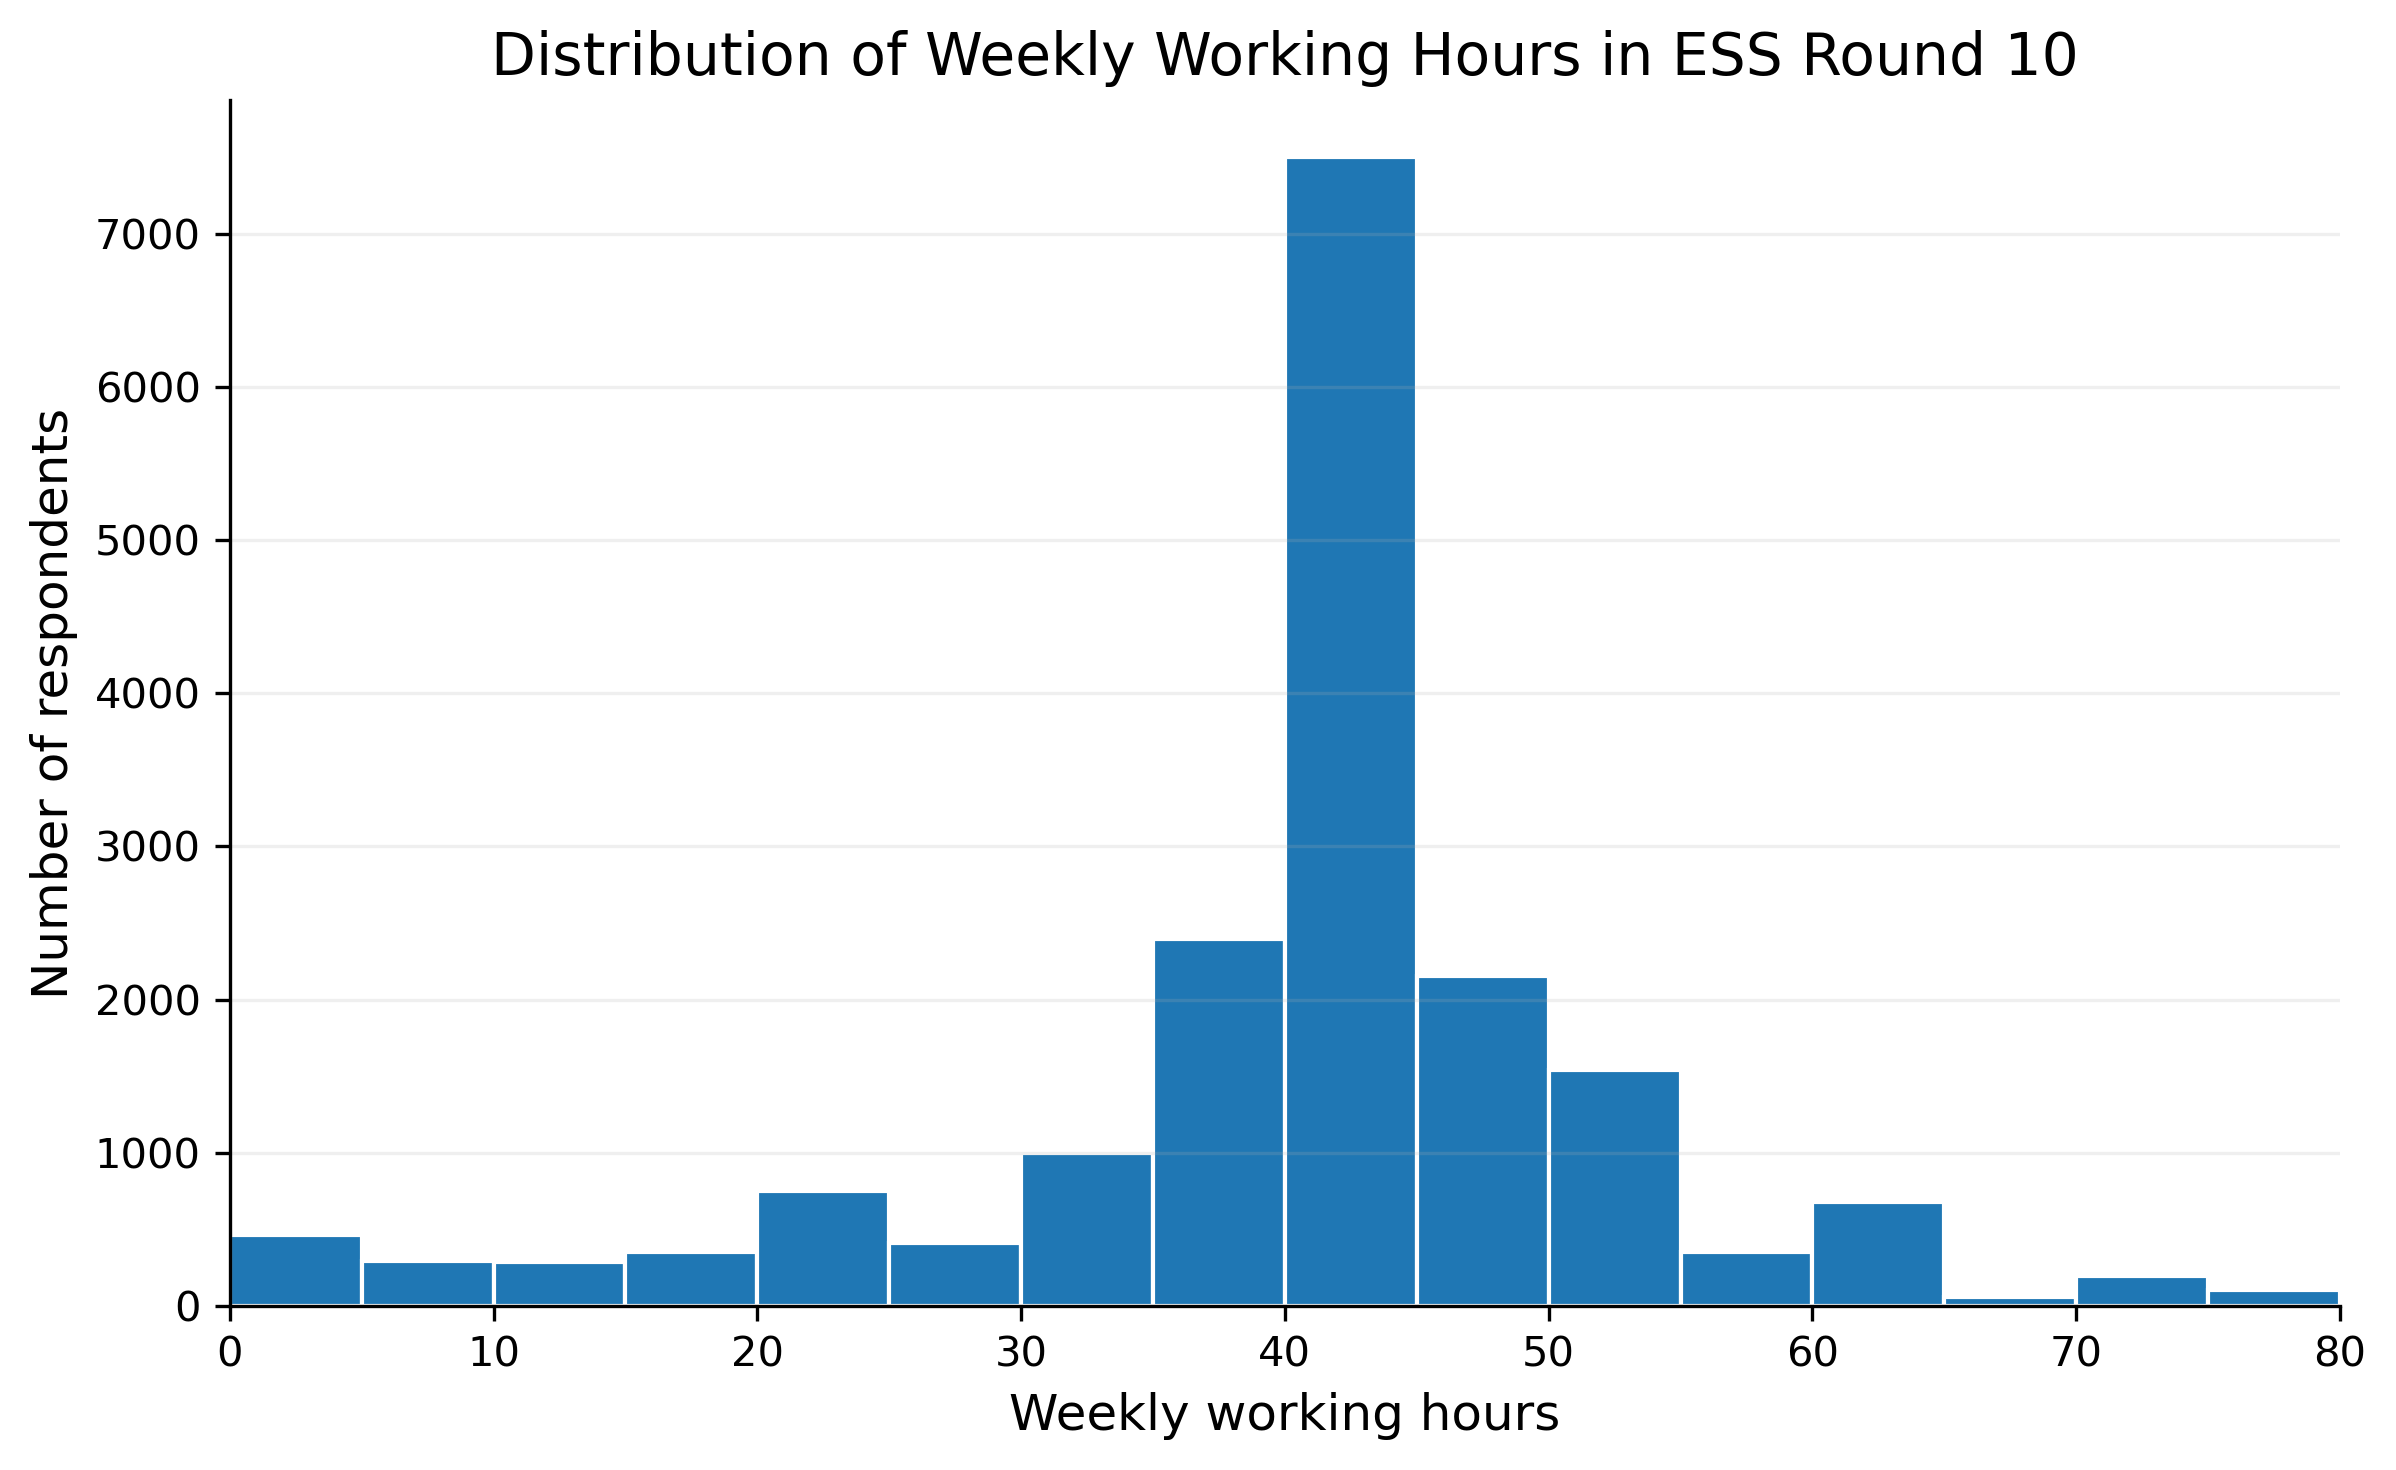

In [80]:
# Step 9.1 Figure 1: Distribution of weekly working hours

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

plot_data = model_sample.loc[
    model_sample["worktime"].between(0, 80),
    "worktime"
]

bins = np.arange(0, 85, 5)

ax.hist(
    plot_data,
    bins=bins,
    edgecolor="white"
)

format_plot(
    ax,
    title="Distribution of Weekly Working Hours in ESS Round 10",
    xlabel="Weekly working hours",
    ylabel="Number of respondents"
)

ax.set_xlim(0, 80)

# Save Figure 1
plt.savefig(
    output_dir / "Figure1_Worktime_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
#The histogram displays respondents working 0–80 hours per week for visual clarity; observations above 80 hours were retained in the statistical analyses.

In [82]:
#fig.2 工作时间与生活满意度

In [83]:
bins = [-np.inf, 30, 40, 50, 60, np.inf]

labels = [
    "<30",
    "30–39",
    "40–49",
    "50–59",
    "≥60"
]

model_sample["worktime_group"] = pd.cut(
    model_sample["worktime"],
    bins=bins,
    labels=labels,
    right=False
)

In [84]:
model_sample["worktime_group"].value_counts().sort_index()

worktime_group
<30      2568
30–39    3398
40–49    9651
50–59    1895
≥60      1178
Name: count, dtype: int64

In [85]:
from scipy.stats import sem, t

In [86]:
group_stats = (
    model_sample
    .groupby("worktime_group", observed=False)["life_satisfaction"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

group_stats["se"] = (
    group_stats["std"] /
    np.sqrt(group_stats["count"])
)

group_stats["ci95"] = (
    1.96 * group_stats["se"]
)

group_stats.round(3)

,worktime_group,count,mean,std,se,ci95
0,<30,2568,7.497,2.010,0.040,0.078
1,30–39,3398,7.590,1.756,0.030,0.059
2,40–49,9651,7.351,1.931,0.020,0.039
3,50–59,1895,7.428,1.861,0.043,0.084
4,≥60,1178,7.376,2.098,0.061,0.120


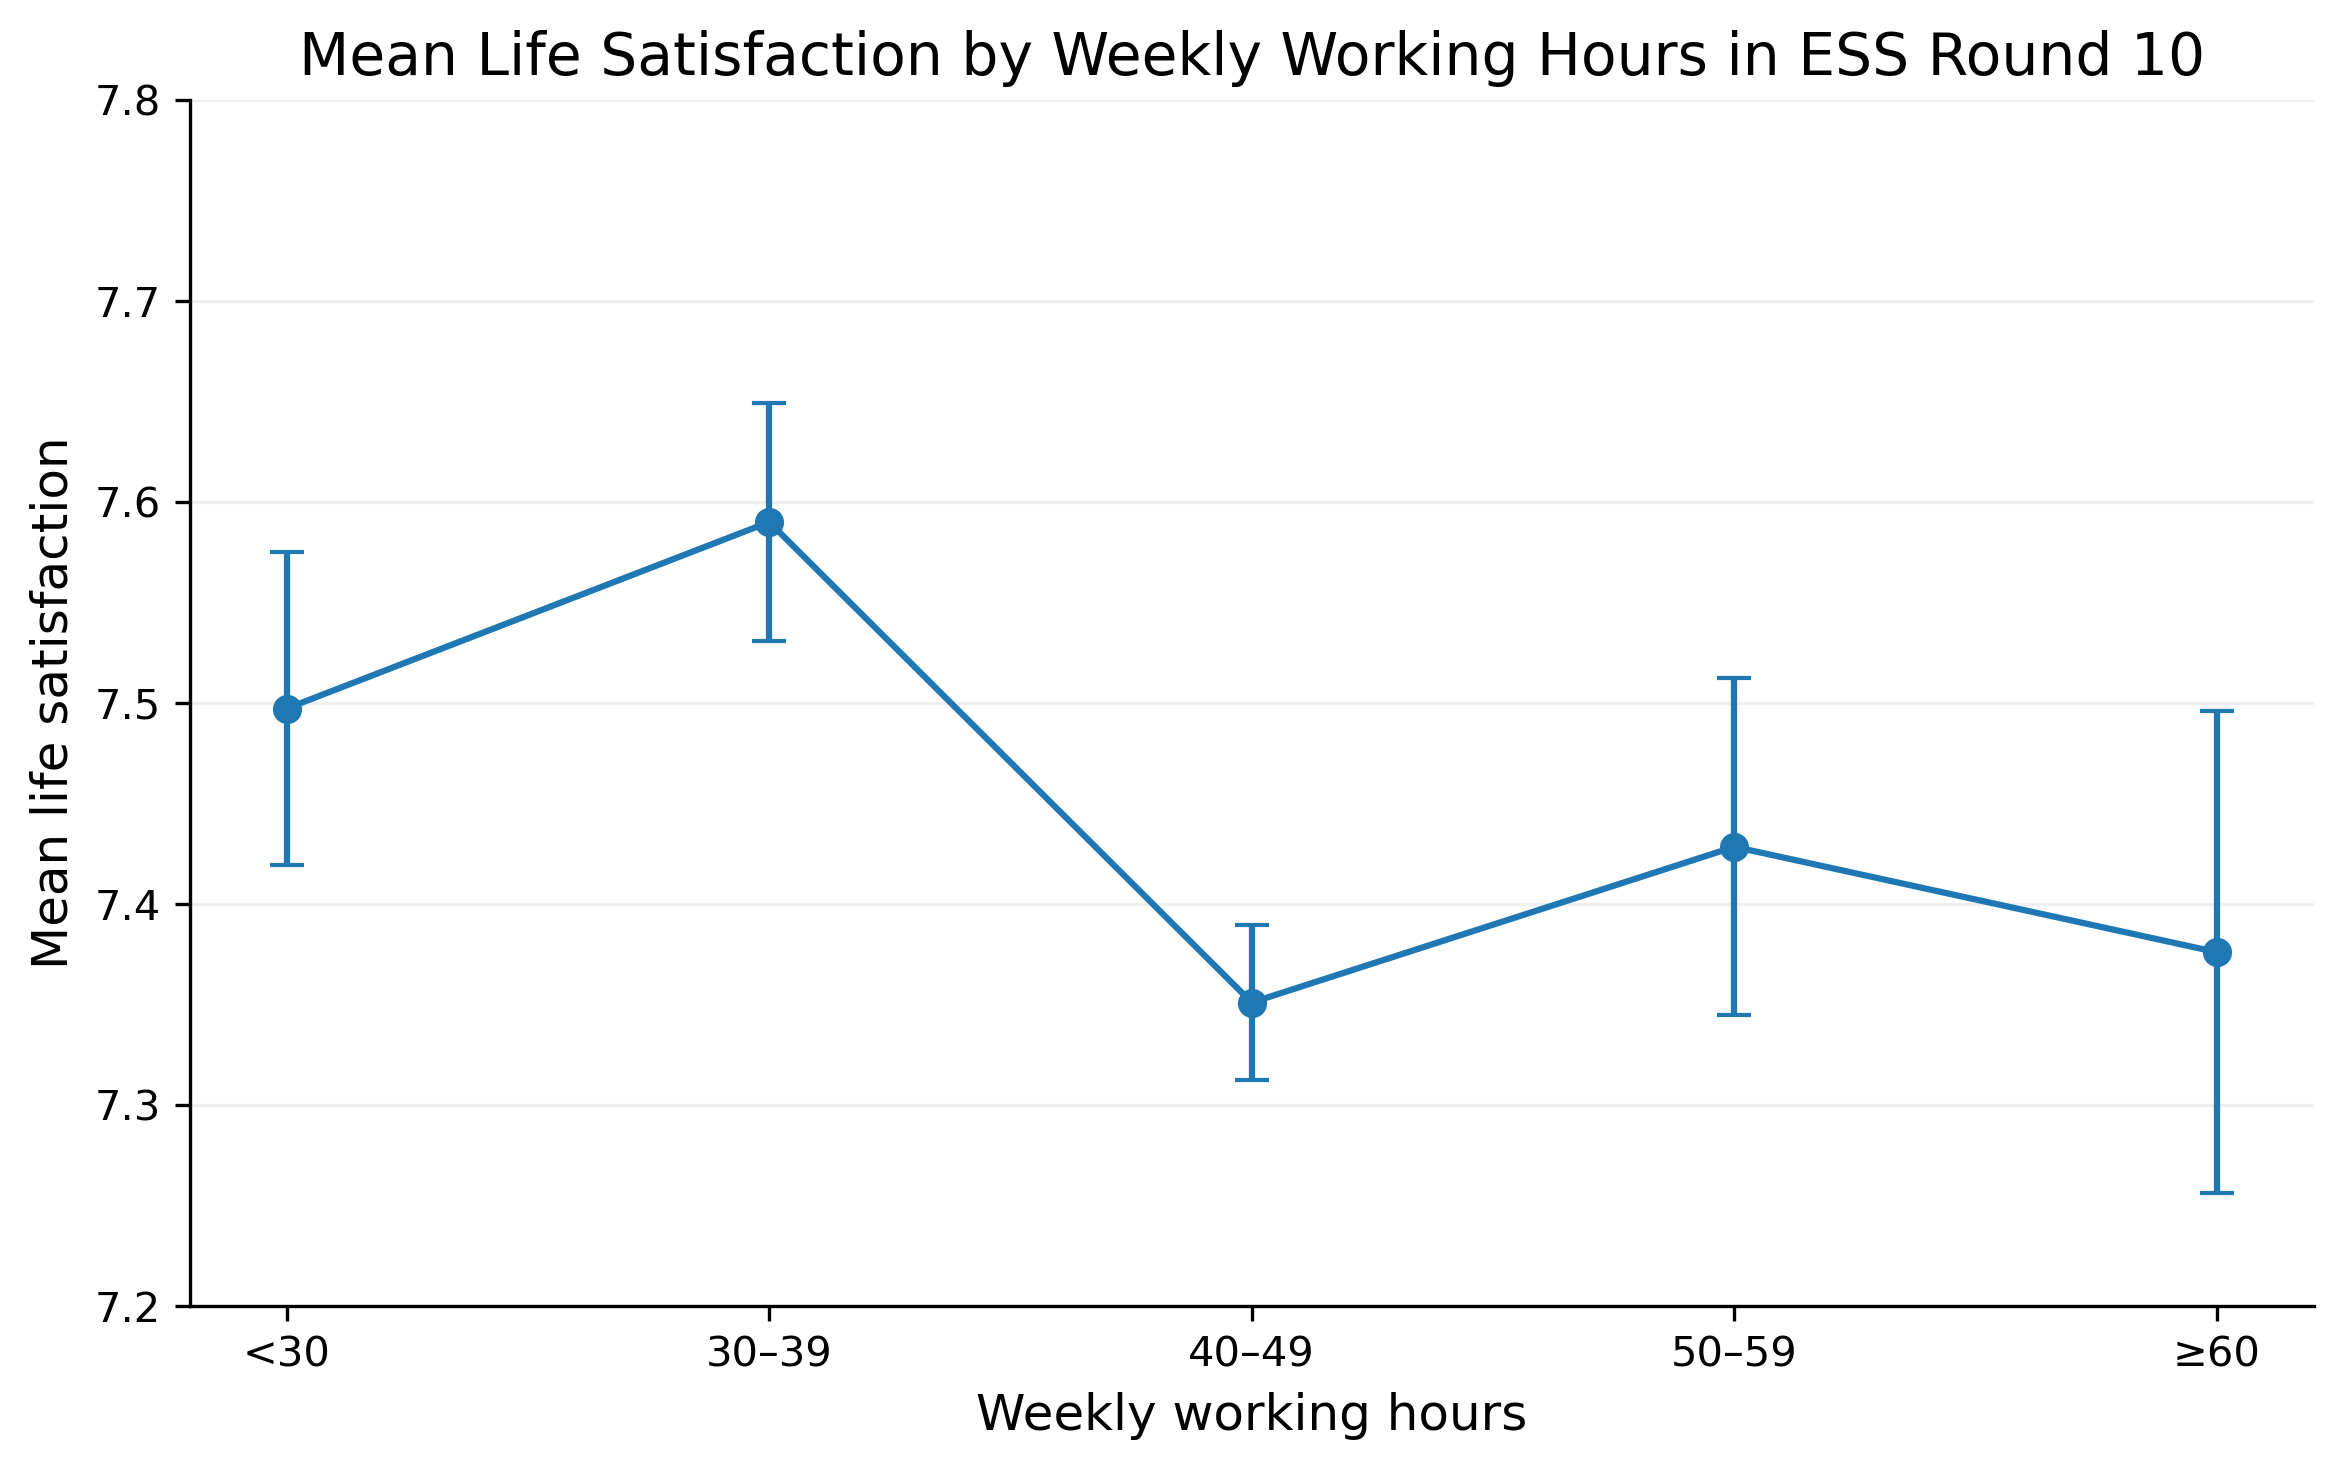

In [87]:
# Step 9.2 Figure 2: Working hours and life satisfaction

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

ax.errorbar(
    group_stats["worktime_group"].astype(str),
    group_stats["mean"],
    yerr=group_stats["ci95"],
    fmt="o-",
    capsize=4,
    linewidth=1.5,
    markersize=6
)

format_plot(
    ax,
    title="Mean Life Satisfaction by Weekly Working Hours in ESS Round 10",
    xlabel="Weekly working hours",
    ylabel="Mean life satisfaction"
)

ax.set_ylim(7.2, 7.8)

# Save Figure 2
plt.savefig(
    output_dir / "Figure2_Worktime_LifeSatisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
#Points represent mean life satisfaction; error bars represent 95% confidence intervals.

In [89]:
group_stats[[
    "worktime_group",
    "count",
    "mean",
    "ci95"
]].round(3)

,worktime_group,count,mean,ci95
0,<30,2568,7.497,0.078
1,30–39,3398,7.590,0.059
2,40–49,9651,7.351,0.039
3,50–59,1895,7.428,0.084
4,≥60,1178,7.376,0.120


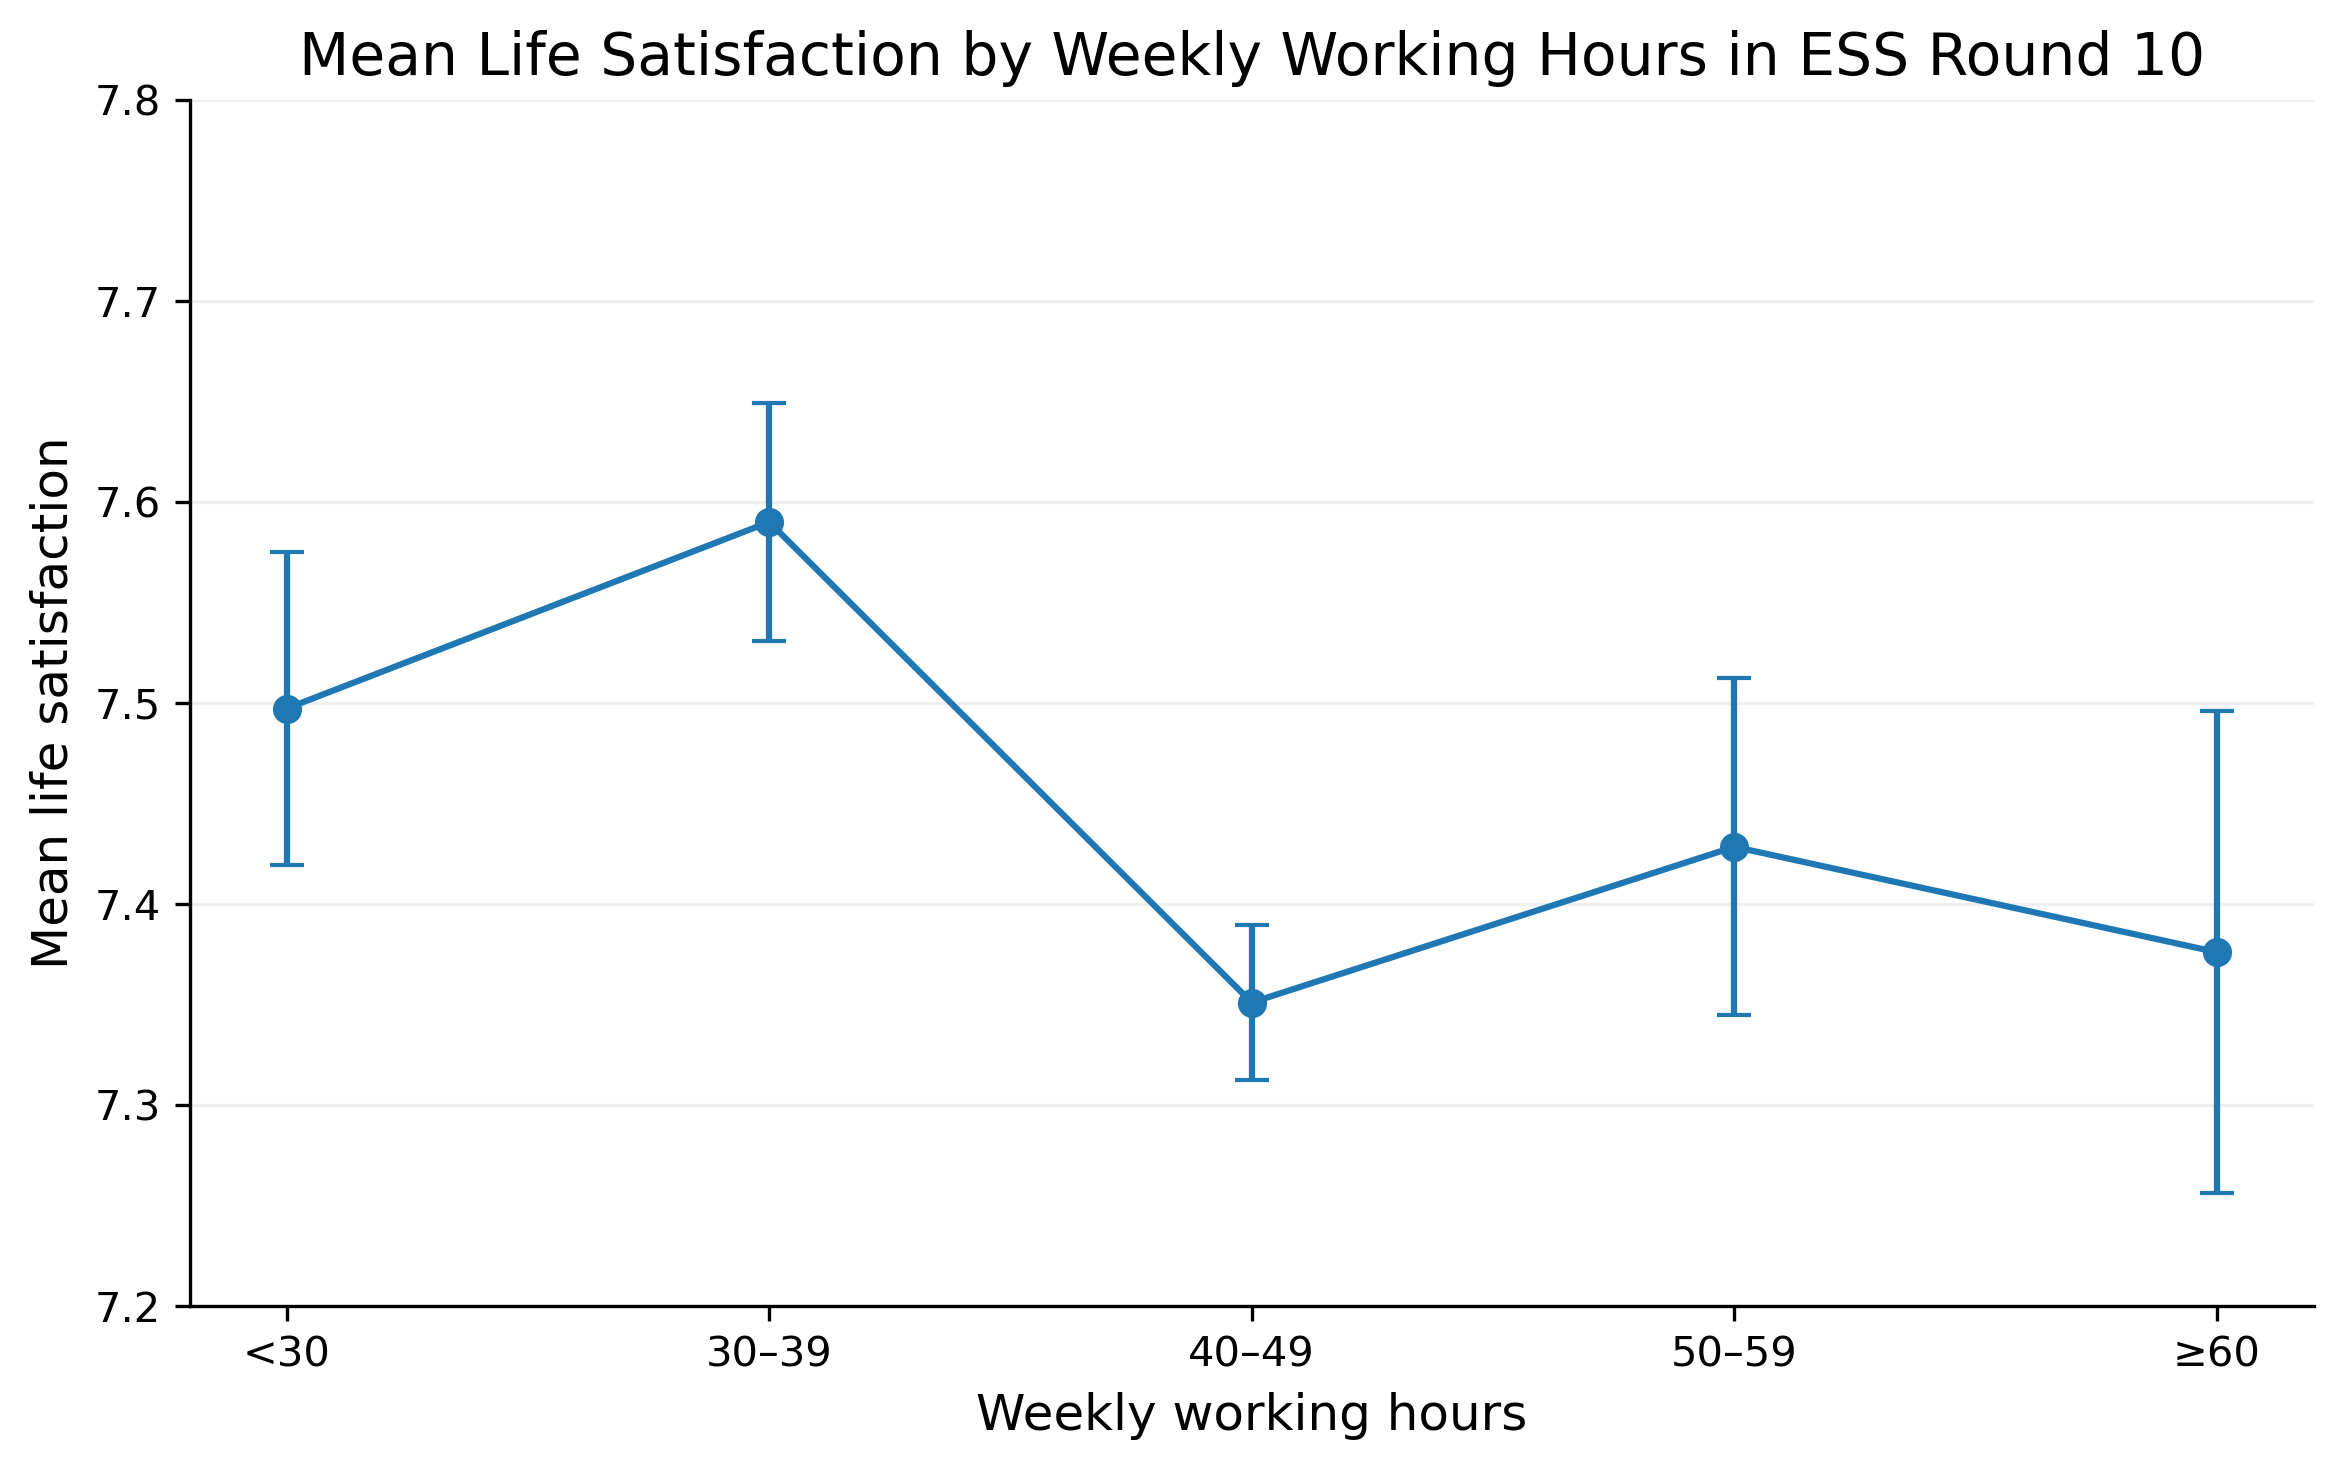

In [90]:
# Figure 2: Working hours and life satisfaction

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

ax.errorbar(
    group_stats["worktime_group"].astype(str),
    group_stats["mean"],
    yerr=group_stats["ci95"],
    fmt="o-",
    capsize=4,
    linewidth=1.5,
    markersize=6
)

format_plot(
    ax,
    title="Mean Life Satisfaction by Weekly Working Hours in ESS Round 10",
    xlabel="Weekly working hours",
    ylabel="Mean life satisfaction"
)

ax.set_ylim(7.2, 7.8)

# Save Figure 2 to outputs folder
plt.savefig(
    output_dir / "Figure2_Worktime_LifeSatisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [91]:
#Mean life satisfaction varied only modestly across working-hour groups. The highest mean was observed among respondents working 30–39 hours per week, while lower values were observed among those working 40 hours or more. The pattern was not strictly monotonic.

#The y-axis is truncated to highlight differences in mean life satisfaction across working-hour groups. Points represent means; error bars represent 95% confidence intervals

In [92]:
#Step10 回归分析+森林图

In [93]:
import statsmodels.api as sm

In [94]:
X = model_sample[
    [
        "worktime",
        "health_clean",
        "social_inclusion",
        "digitalization",
        "trust",
        "safety",
        "income",
        "gender",
        "age",
        "married",
        "religion",
        "education"
    ]
]

y = model_sample["life_satisfaction"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      life_satisfaction   R-squared:                       0.181
Model:                            OLS   Adj. R-squared:                  0.181
Method:                 Least Squares   F-statistic:                     344.6
Date:                Tue, 15 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:49:22   Log-Likelihood:                -36822.
No. Observations:               18690   AIC:                         7.367e+04
Df Residuals:                   18677   BIC:                         7.377e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                2.1914      0.110  

In [95]:
#Model 1：只放工作时间

In [96]:
X1 = sm.add_constant(
    model_sample[["worktime"]]
)

model1 = sm.OLS(
    model_sample["life_satisfaction"],
    X1
).fit()

In [97]:
#Model 2：加人口学因素

In [98]:
X2 = sm.add_constant(
    model_sample[
        [
            "worktime",
            "gender",
            "age",
            "married",
            "religion",
            "education",
            "income"
        ]
    ]
)

model2 = sm.OLS(
    model_sample["life_satisfaction"],
    X2
).fit()

In [99]:
#Model 3：完整模型

In [100]:
X3 = sm.add_constant(
    model_sample[
        [
            "worktime",
            "gender",
            "age",
            "married",
            "religion",
            "education",
            "income",
            "health_clean",
            "social_inclusion",
            "digitalization",
            "trust",
            "safety"
        ]
    ]
)

model3 = sm.OLS(
    model_sample["life_satisfaction"],
    X3
).fit()

In [101]:
comparison = pd.DataFrame({
    "Model 1": [
        model1.params["worktime"],
        model1.pvalues["worktime"],
        model1.rsquared
    ],
    "Model 2": [
        model2.params["worktime"],
        model2.pvalues["worktime"],
        model2.rsquared
    ],
    "Model 3": [
        model3.params["worktime"],
        model3.pvalues["worktime"],
        model3.rsquared
    ]
}, index=[
    "Worktime coefficient",
    "P value",
    "R-squared"
])

comparison.round(4)

,Model 1,Model 2,Model 3
Worktime coefficient,-0.0035,-0.0062,-0.0040
P value,0.0002,0.0000,0.0000
R-squared,0.0007,0.0563,0.1813


In [102]:
#森林图

In [103]:
coef_table = pd.DataFrame({
    "variable": model3.params.index,
    "coef": model3.params.values,
    "lower": model3.conf_int()[0].values,
    "upper": model3.conf_int()[1].values,
    "pvalue": model3.pvalues.values
})

In [104]:
coef_table = coef_table[
    coef_table["variable"] != "const"
].copy()

In [105]:
label_map = {
    "worktime": "Weekly working hours",
    "gender": "Gender",
    "age": "Age",
    "married": "Marital status",
    "religion": "Religion",
    "education": "Education",
    "income": "Income",
    "health_clean": "Health",
    "social_inclusion": "Social inclusion",
    "digitalization": "Digitalization",
    "trust": "Social trust",
    "safety": "Safety"
}

coef_table["label"] = coef_table["variable"].map(label_map)

In [106]:
order = [
    "Weekly working hours",
    "Age",
    "Gender",
    "Education",
    "Income",
    "Marital status",
    "Religion",
    "Health",
    "Social inclusion",
    "Digitalization",
    "Social trust",
    "Safety"
]

coef_table["label"] = pd.Categorical(
    coef_table["label"],
    categories=order,
    ordered=True
)

coef_table = coef_table.sort_values("label")

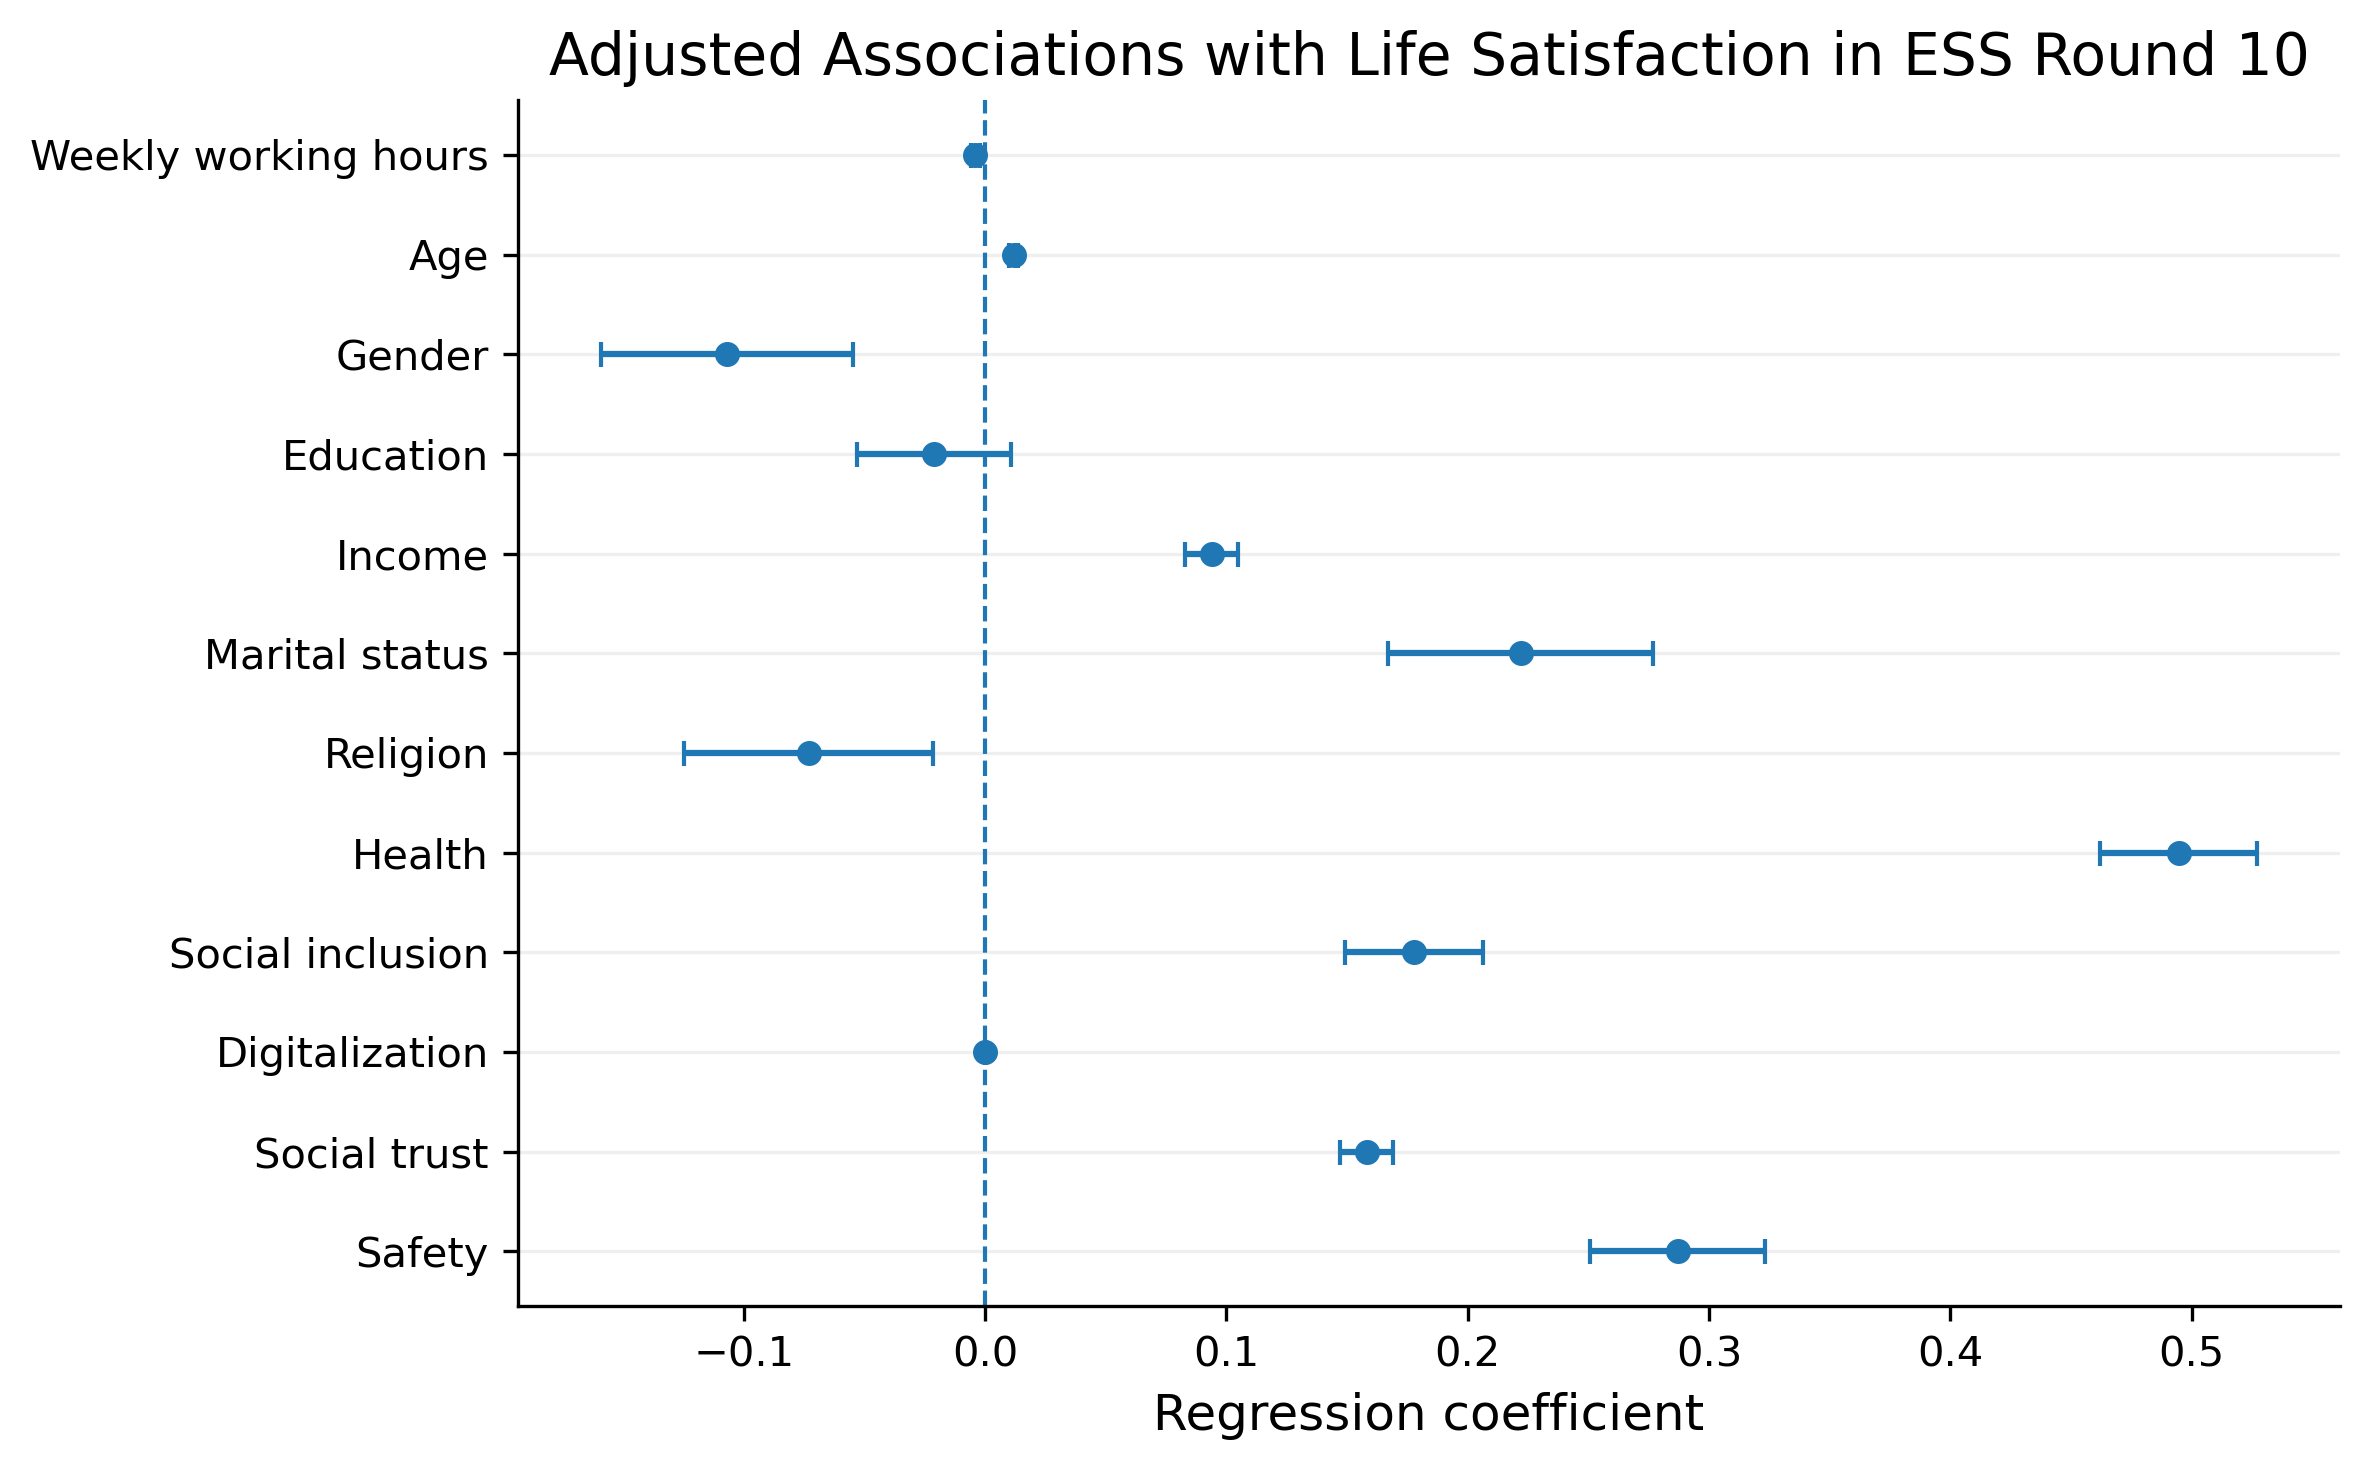

In [107]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

y_pos = np.arange(len(coef_table))

ax.errorbar(
    coef_table["coef"],
    y_pos,
    xerr=[
        coef_table["coef"] - coef_table["lower"],
        coef_table["upper"] - coef_table["coef"]
    ],
    fmt="o",
    capsize=3,
    markersize=5
)

ax.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y_pos)
ax.set_yticklabels(coef_table["label"])
ax.invert_yaxis()

format_plot(
    ax,
    title="Adjusted Associations with Life Satisfaction in ESS Round 10",
    xlabel="Regression coefficient",
    ylabel=""
)

plt.savefig(
    output_dir / "Fig3_ESS10_regression_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [108]:
result_table = pd.DataFrame({
    "Coefficient": model3.params,
    "Lower 95% CI": model3.conf_int()[0],
    "Upper 95% CI": model3.conf_int()[1],
    "P value": model3.pvalues
})
result_table.round(4)

,Coefficient,Lower 95% CI,Upper 95% CI,P value
const,2.1914,1.9751,2.4078,0.0000
worktime,-0.0040,-0.0057,-0.0023,0.0000
gender,-0.1070,-0.1592,-0.0548,0.0001
age,0.0118,0.0100,0.0137,0.0000
married,0.2220,0.1671,0.2769,0.0000
religion,-0.0731,-0.1247,-0.0215,0.0055
education,-0.0212,-0.0530,0.0106,0.1918
income,0.0939,0.0831,0.1047,0.0000
health_clean,0.4946,0.4620,0.5272,0.0000
social_inclusion,0.1778,0.1491,0.2064,0.0000


In [109]:
# Common covariates for Models 1 and 2
common_vars = [
    "worktime",
    "trust",
    "social_inclusion",
    "safety",
    "digitalization",
    "gender",
    "age",
    "married",
    "religion",
    "education",
    "income"
]


# -------------------------
# Model 1
# Outcome: Life satisfaction
# -------------------------

X1 = sm.add_constant(
    model_sample[common_vars]
)

y1 = model_sample["life_satisfaction"]

model1 = sm.OLS(
    y1,
    X1
).fit()


# -------------------------
# Model 2
# Outcome: Health
# -------------------------

X2 = sm.add_constant(
    model_sample[common_vars]
)

y2 = model_sample["health_clean"]

model2 = sm.OLS(
    y2,
    X2
).fit()


# -------------------------
# Model 3
# Outcome: Life satisfaction
# Add health as mediator
# -------------------------

model3_vars = [
    "worktime",
    "health_clean",
    "trust",
    "social_inclusion",
    "safety",
    "digitalization",
    "gender",
    "age",
    "married",
    "religion",
    "education",
    "income"
]

X3 = sm.add_constant(
    model_sample[model3_vars]
)

y3 = model_sample["life_satisfaction"]

model3 = sm.OLS(
    y3,
    X3
).fit()

In [110]:
print(
    "Model 1 - Worktime → Life satisfaction:",
    round(model1.params["worktime"], 4),
    "p =",
    round(model1.pvalues["worktime"], 4)
)

print(
    "Model 2 - Worktime → Health:",
    round(model2.params["worktime"], 4),
    "p =",
    round(model2.pvalues["worktime"], 4)
)

print(
    "Model 3 - Worktime → Life satisfaction:",
    round(model3.params["worktime"], 4),
    "p =",
    round(model3.pvalues["worktime"], 4)
)

print(
    "Model 3 - Health → Life satisfaction:",
    round(model3.params["health_clean"], 4),
    "p =",
    round(model3.pvalues["health_clean"], 4)
)

Model 1 - Worktime → Life satisfaction: -0.0037 p = 0.0
Model 2 - Worktime → Health: 0.0006 p = 0.1317
Model 3 - Worktime → Life satisfaction: -0.004 p = 0.0
Model 3 - Health → Life satisfaction: 0.4946 p = 0.0


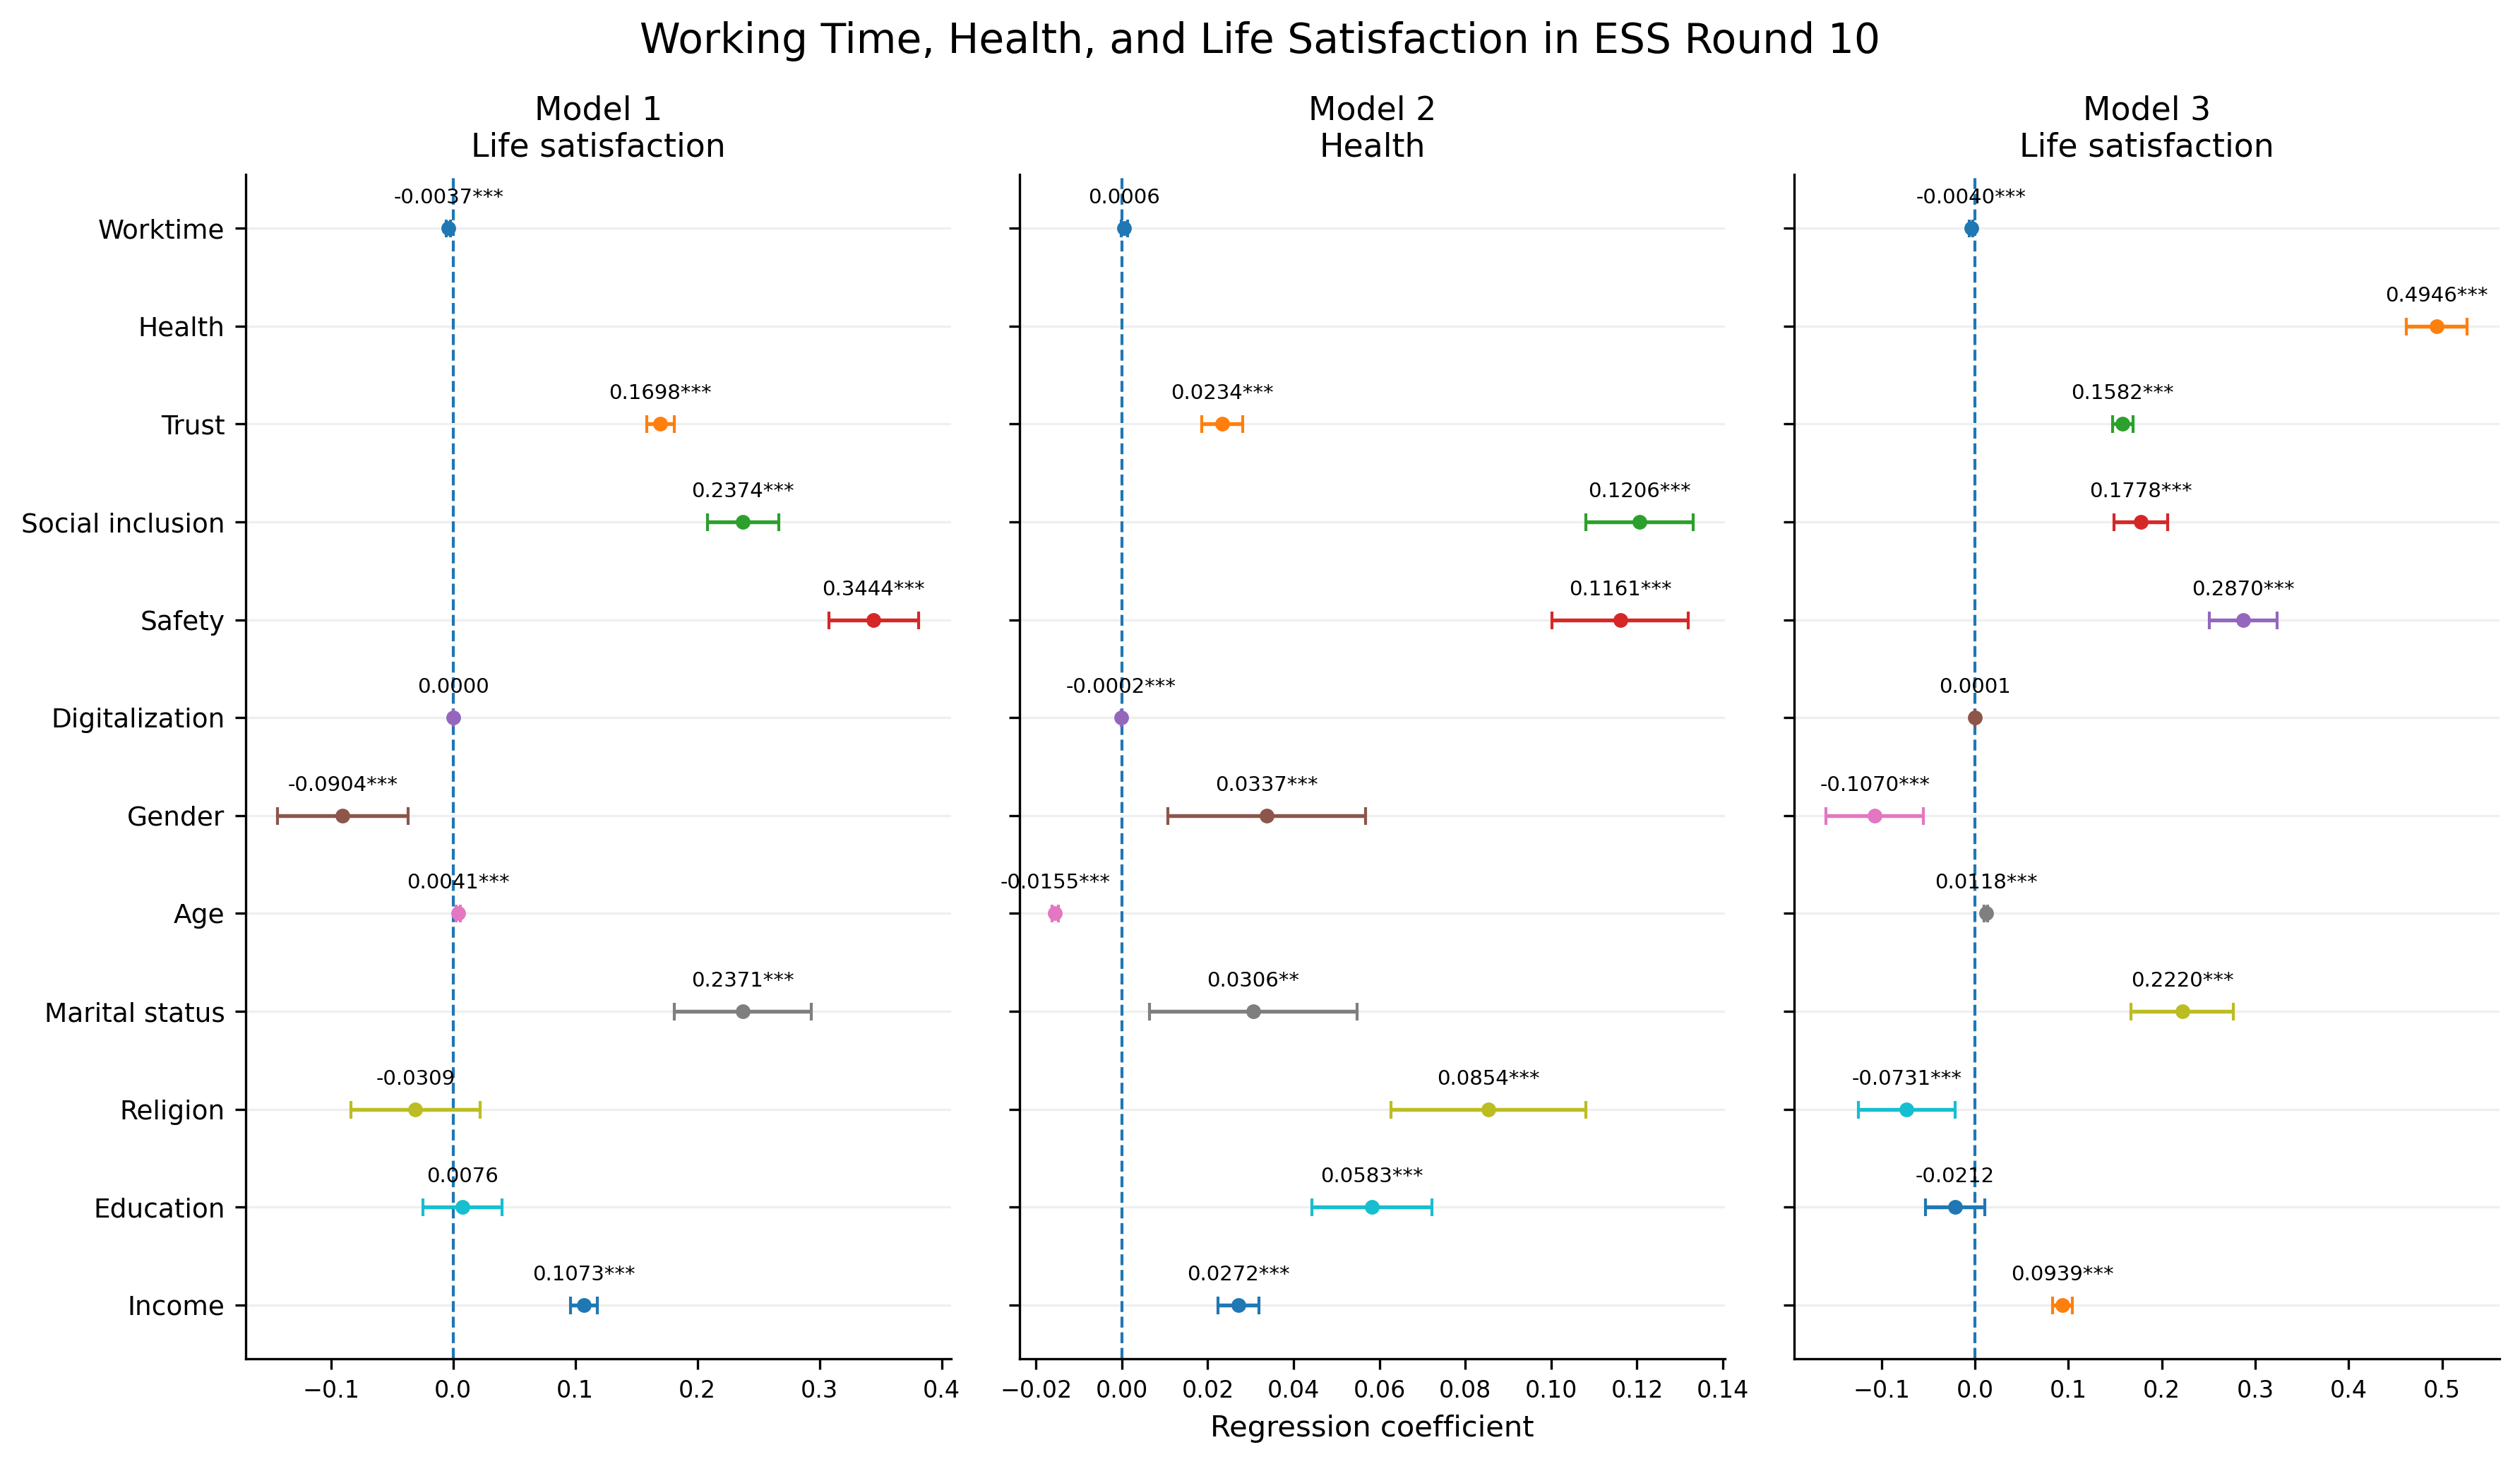

In [111]:
# Step 10.6 Three-panel coefficient plot

import numpy as np
import matplotlib.pyplot as plt

# Variables displayed in the figure
plot_vars = [
    "worktime",
    "health_clean",
    "trust",
    "social_inclusion",
    "safety",
    "digitalization",
    "gender",
    "age",
    "married",
    "religion",
    "education",
    "income"
]

plot_labels = [
    "Worktime",
    "Health",
    "Trust",
    "Social inclusion",
    "Safety",
    "Digitalization",
    "Gender",
    "Age",
    "Marital status",
    "Religion",
    "Education",
    "Income"
]

models = [model1, model2, model3]

titles = [
    "Model 1\nLife satisfaction",
    "Model 2\nHealth",
    "Model 3\nLife satisfaction"
]


# Function for significance stars
def sig_stars(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.10:
        return "*"
    else:
        return ""


fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 7),
    dpi=300,
    sharey=True
)

y_positions = np.arange(len(plot_vars))


for ax, model, title in zip(axes, models, titles):

    # Zero reference line
    ax.axvline(
        x=0,
        linestyle="--",
        linewidth=1
    )

    for i, var in enumerate(plot_vars):

        # Only plot variables included in the model
        if var in model.params.index:

            coef = model.params[var]

            lower = model.conf_int().loc[var, 0]
            upper = model.conf_int().loc[var, 1]

            p = model.pvalues[var]

            # Point + 95% CI
            ax.errorbar(
                coef,
                i,
                xerr=[
                    [coef - lower],
                    [upper - coef]
                ],
                fmt="o",
                capsize=3,
                markersize=4,
                linewidth=1.3
            )

            # Coefficient label
            text = f"{coef:.4f}{sig_stars(p)}"

            ax.annotate(
                text,
                xy=(coef, i),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=7
            )

    ax.set_title(
        title,
        fontsize=11
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        plot_labels,
        fontsize=9
    )

    ax.grid(
        axis="y",
        alpha=0.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="x",
        labelsize=8
    )


# Same variable order as paper
axes[0].invert_yaxis()

# Axis label
axes[1].set_xlabel(
    "Regression coefficient",
    fontsize=10
)

plt.suptitle(
    "Working Time, Health, and Life Satisfaction in ESS Round 10",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "Fig3_ESS10_three_model_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
#OLS vs ordered probit。检查是数据问题还是模型问题，导致health的中介不显著

In [113]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

In [114]:
common_vars = [
    "worktime",
    "trust",
    "social_inclusion",
    "safety",
    "digitalization",
    "gender",
    "age",
    "married",
    "religion",
    "education",
    "income"
]

ordered_model1 = OrderedModel(
    model_sample["life_satisfaction"].astype(int),
    model_sample[common_vars].astype(float),
    distr="probit"
)

ordered_result1 = ordered_model1.fit(
    method="bfgs",
    maxiter=500,
    disp=False
)

print(ordered_result1.summary())

                             OrderedModel Results                             
Dep. Variable:      life_satisfaction   Log-Likelihood:                -34926.
Model:                   OrderedModel   AIC:                         6.989e+04
Method:            Maximum Likelihood   BIC:                         7.006e+04
Date:                Tue, 15 Sep 2026                                         
Time:                        13:49:40                                         
No. Observations:               18690                                         
Df Residuals:                   18669                                         
Df Model:                          11                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
worktime            -0.0021      0.001     -4.029      0.000      -0.003      -0.001
trust                0.0918      0

In [115]:
print(
    "Model 1 - Worktime:",
    ordered_result1.params["worktime"],
    "p =",
    ordered_result1.pvalues["worktime"]
)

Model 1 - Worktime: -0.002084141134893128 p = 5.590796212922015e-05


In [116]:
ordered_model2 = OrderedModel(
    model_sample["health_clean"].astype(int),
    model_sample[common_vars].astype(float),
    distr="probit"
)

ordered_result2 = ordered_model2.fit(
    method="bfgs",
    maxiter=500,
    disp=False
)

print(ordered_result2.summary())

                             OrderedModel Results                             
Dep. Variable:           health_clean   Log-Likelihood:                -20645.
Model:                   OrderedModel   AIC:                         4.132e+04
Method:            Maximum Likelihood   BIC:                         4.144e+04
Date:                Tue, 15 Sep 2026                                         
Time:                        13:49:48                                         
No. Observations:               18690                                         
Df Residuals:                   18675                                         
Df Model:                          11                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
worktime             0.0009      0.001      1.604      0.109      -0.000       0.002
trust                0.0324      0

In [117]:
print(
    "Model 2 - Worktime:",
    ordered_result2.params["worktime"],
    "p =",
    ordered_result2.pvalues["worktime"]
)

Model 2 - Worktime: 0.0008886116534816893 p = 0.10866975450319998


In [118]:
model3_vars = [
    "worktime",
    "health_clean",
    "trust",
    "social_inclusion",
    "safety",
    "digitalization",
    "gender",
    "age",
    "married",
    "religion",
    "education",
    "income"
]

ordered_model3 = OrderedModel(
    model_sample["life_satisfaction"].astype(int),
    model_sample[model3_vars].astype(float),
    distr="probit"
)

ordered_result3 = ordered_model3.fit(
    method="bfgs",
    maxiter=500,
    disp=False
)

print(ordered_result3.summary())

                             OrderedModel Results                             
Dep. Variable:      life_satisfaction   Log-Likelihood:                -34514.
Model:                   OrderedModel   AIC:                         6.907e+04
Method:            Maximum Likelihood   BIC:                         6.924e+04
Date:                Tue, 15 Sep 2026                                         
Time:                        13:50:05                                         
No. Observations:               18690                                         
Df Residuals:                   18668                                         
Df Model:                          12                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
worktime            -0.0023      0.001     -4.436      0.000      -0.003      -0.001
health_clean         0.2852      0

In [119]:
print(
    "Model 3 - Worktime:",
    ordered_result3.params["worktime"],
    "p =",
    ordered_result3.pvalues["worktime"]
)

print(
    "Model 3 - Health:",
    ordered_result3.params["health_clean"],
    "p =",
    ordered_result3.pvalues["health_clean"]
)

Model 3 - Worktime: -0.002297143110984875 p = 9.16355353624341e-06
Model 3 - Health: 0.2852243986818676 p = 5.236423317505417e-181


In [120]:
#OLS:             p = 0.132
#Ordered Probit:  p = 0.109
#不是模型的问题导致健康不显著，可能是数据的问题。要不要深究

In [121]:
#导出

In [122]:
# Step 11.1 Create output folder

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

print("Output folder:", output_dir.resolve())

Output folder: C:\Users\20496\Desktop\ESS10_analysis\outputs


In [124]:
# Step 11.2 Export descriptive statistics
continuous_vars = [
    "life_satisfaction",
    "worktime",
    "health_clean",
    "social_inclusion",
    "digitalization",
    "trust",
    "safety",
    "income",
    "age"
]

desc_table = model_sample[continuous_vars].describe().T[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(3)

desc_table.to_csv(
    output_dir / "Table1_Descriptive_statistics.csv"
)

desc_table

,count,mean,std,min,25%,50%,75%,max
life_satisfaction,18690.0,7.424,1.918,0.0,7.0,8.0,9.0,10.0
worktime,18690.0,39.602,14.780,0.0,37.0,40.0,45.0,168.0
health_clean,18690.0,4.009,0.826,1.0,4.0,4.0,5.0,5.0
social_inclusion,18690.0,2.774,0.888,1.0,2.0,3.0,3.0,5.0
digitalization,18690.0,227.862,187.530,0.0,90.0,180.0,300.0,1440.0
trust,18690.0,5.444,2.418,0.0,4.0,6.0,7.0,10.0
safety,18690.0,3.177,0.733,1.0,3.0,3.0,4.0,4.0
income,18690.0,6.022,2.597,1.0,4.0,6.0,8.0,10.0
age,18690.0,47.611,15.646,15.0,35.0,47.0,59.0,90.0


In [125]:
# Step 11.3 Export categorical summaries

gender_table = categorical_summary(
    model_sample,
    "gender",
    gender_labels
)

married_table = categorical_summary(
    model_sample,
    "married",
    married_labels
)

religion_table = categorical_summary(
    model_sample,
    "religion",
    religion_labels
)

education_table = categorical_summary(
    model_sample,
    "education",
    education_labels
)

job_table = categorical_summary(
    job_sample,
    "job_category",
    job_labels
)

gender_table.to_csv(
    output_dir / "Table2a_Gender.csv",
    index=False
)

married_table.to_csv(
    output_dir / "Table2b_Marital_status.csv",
    index=False
)

religion_table.to_csv(
    output_dir / "Table2c_Religion.csv",
    index=False
)

education_table.to_csv(
    output_dir / "Table2d_Education.csv",
    index=False
)

job_table.to_csv(
    output_dir / "Table2e_Job_category.csv",
    index=False
)

In [126]:
# Step 11.4 Export correlation matrix

corr_matrix.round(3).to_csv(
    output_dir / "Table3_Correlation_matrix.csv"
)

corr_matrix.round(3)

,life_satisfaction,worktime,health_clean,social_inclusion,digitalization,trust,safety,income,gender,age,married,religion,education
life_satisfaction,1.000,-0.027,0.254,0.150,0.030,0.279,0.200,0.211,0.025,0.036,0.115,-0.038,0.098
worktime,-0.027,1.000,0.008,-0.001,0.009,-0.064,0.028,0.078,0.149,0.048,0.041,0.036,0.022
health_clean,0.254,0.008,1.000,0.157,0.082,0.098,0.149,0.175,0.053,-0.284,-0.019,0.010,0.103
social_inclusion,0.150,-0.001,0.157,1.000,0.012,0.090,0.057,0.099,0.029,-0.003,-0.002,0.042,0.075
digitalization,0.030,0.009,0.082,0.012,1.000,0.063,0.051,0.144,0.015,-0.307,-0.121,-0.120,0.186
trust,0.279,-0.064,0.098,0.090,0.063,1.000,0.218,0.134,0.011,0.056,0.029,-0.124,0.162
safety,0.200,0.028,0.149,0.057,0.051,0.218,1.000,0.135,0.238,-0.030,0.044,-0.083,0.068
income,0.211,0.078,0.175,0.099,0.144,0.134,0.135,1.000,0.095,-0.131,0.245,-0.061,0.270
gender,0.025,0.149,0.053,0.029,0.015,0.011,0.238,0.095,1.000,0.004,0.023,-0.064,-0.037
age,0.036,0.048,-0.284,-0.003,-0.307,0.056,-0.030,-0.131,0.004,1.000,0.273,0.098,-0.002


In [127]:
corr_with_worktime.round(3).to_csv(
    output_dir / "Table3b_Correlations_with_worktime.csv"
)

In [128]:
# Step 11.5 Create regression results table

def extract_model_results(result, model_name):
    
    ci = result.conf_int()
    
    rows = []
    
    variables = [
        "worktime",
        "health_clean",
        "trust",
        "social_inclusion",
        "safety",
        "digitalization",
        "gender",
        "age",
        "married",
        "religion",
        "education",
        "income"
    ]
    
    for var in variables:
        
        if var in result.params.index:
            
            rows.append({
                "Model": model_name,
                "Variable": var,
                "Coefficient": result.params[var],
                "SE": result.bse[var],
                "P_value": result.pvalues[var],
                "Lower_95CI": ci.loc[var, 0],
                "Upper_95CI": ci.loc[var, 1]
            })
    
    return pd.DataFrame(rows)

In [129]:
reg1 = extract_model_results(
    ordered_result1,
    "Model 1: Life satisfaction"
)

reg2 = extract_model_results(
    ordered_result2,
    "Model 2: Health"
)

reg3 = extract_model_results(
    ordered_result3,
    "Model 3: Life satisfaction + Health"
)

regression_table = pd.concat(
    [reg1, reg2, reg3],
    ignore_index=True
)

regression_table = regression_table.round(4)

regression_table.to_csv(
    output_dir / "Table4_Ordered_Probit_results.csv",
    index=False
)

regression_table

,Model,Variable,Coefficient,SE,P_value,Lower_95CI,Upper_95CI
0,Model 1: Life satisfaction,worktime,-0.0021,0.0005,0.0001,-0.0031,-0.0011
1,Model 1: Life satisfaction,trust,0.0918,0.0033,0.0000,0.0853,0.0983
2,Model 1: Life satisfaction,social_inclusion,0.1338,0.0086,0.0000,0.1169,0.1506
3,Model 1: Life satisfaction,safety,0.2052,0.0109,0.0000,0.1838,0.2266
4,Model 1: Life satisfaction,digitalization,0.0001,0.0000,0.1622,-0.0000,0.0001
5,Model 1: Life satisfaction,gender,-0.0618,0.0157,0.0001,-0.0926,-0.0309
6,Model 1: Life satisfaction,age,0.0030,0.0005,0.0000,0.0020,0.0041
7,Model 1: Life satisfaction,married,0.1515,0.0166,0.0000,0.1190,0.1840
8,Model 1: Life satisfaction,religion,-0.0170,0.0156,0.2739,-0.0475,0.0135
9,Model 1: Life satisfaction,education,-0.0043,0.0096,0.6501,-0.0231,0.0144


In [130]:
plt.savefig(
    output_dir / "Figure1_Worktime_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 2400x1500 with 0 Axes>

In [131]:
plt.savefig(
    output_dir / "Figure2_Worktime_LifeSatisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 2400x1500 with 0 Axes>

In [132]:
plt.savefig(
    output_dir / "Figure3_OrderedProbit_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 2400x1500 with 0 Axes>

In [133]:
# Step 11.6 Check exported files

for file in sorted(output_dir.iterdir()):
    print(file.name)

Fig3_ESS10_regression_forest.png
Figure1_Worktime_distribution.png
Figure2_Worktime_LifeSatisfaction.png
Figure3_OrderedProbit_models.png
Table1_Descriptive_statistics.csv
Table2_Categorical_characteristics.csv
Table2a_Gender.csv
Table2b_Marital_status.csv
Table2c_Religion.csv
Table2d_Education.csv
Table2e_Job_category.csv
Table3_Correlation_matrix.csv
Table3b_Correlations_with_worktime.csv
Table4_Ordered_Probit_results.csv


In [134]:
# Merge Table 2 categorical characteristics

table2 = pd.concat(
    [
        pd.read_csv(output_dir / "Table2a_Gender.csv"),
        pd.read_csv(output_dir / "Table2b_Marital_status.csv"),
        pd.read_csv(output_dir / "Table2c_Religion.csv"),
        pd.read_csv(output_dir / "Table2d_Education.csv"),
        pd.read_csv(output_dir / "Table2e_Job_category.csv")
    ],
    ignore_index=True
)

table2.to_csv(
    output_dir / "Table2_Categorical_characteristics.csv",
    index=False
)

table2

,Category,N,Percent
0,Female,9725,52.03
1,Male,8965,47.97
2,Not married,9356,50.06
3,Married,9334,49.94
4,No,8619,46.12
5,Yes,10071,53.88
6,High school or lower,11744,62.84
7,Bachelor's degree,3260,17.44
8,Master's degree,3397,18.18
9,Doctoral degree,289,1.55


In [135]:
old_files = [
    "Table2a_Gender.csv",
    "Table2b_Marital_status.csv",
    "Table2c_Religion.csv",
    "Table2d_Education.csv",
    "Table2e_Job_category.csv"
]

for name in old_files:
    path = output_dir / name
    if path.exists():
        path.unlink()

print("Old Table 2 files removed.")

Old Table 2 files removed.


In [136]:
for file in sorted(output_dir.iterdir()):
    print(file.name)

Fig3_ESS10_regression_forest.png
Figure1_Worktime_distribution.png
Figure2_Worktime_LifeSatisfaction.png
Figure3_OrderedProbit_models.png
Table1_Descriptive_statistics.csv
Table2_Categorical_characteristics.csv
Table3_Correlation_matrix.csv
Table3b_Correlations_with_worktime.csv
Table4_Ordered_Probit_results.csv


In [137]:
extra_file = output_dir / "Table3b_Correlations_with_worktime.csv"

if extra_file.exists():
    extra_file.unlink()

print("Extra correlation file removed.")

Extra correlation file removed.


In [138]:
for file in sorted(output_dir.iterdir()):
    print(file.name)

Fig3_ESS10_regression_forest.png
Figure1_Worktime_distribution.png
Figure2_Worktime_LifeSatisfaction.png
Figure3_OrderedProbit_models.png
Table1_Descriptive_statistics.csv
Table2_Categorical_characteristics.csv
Table3_Correlation_matrix.csv
Table4_Ordered_Probit_results.csv


In [ ]:
#合并图2

In [139]:
group_stats.to_csv(
    "ESS10_worktime_lifesatisfaction_summary.csv",
    index=False
)

ESS10:


,worktime_group,count,mean,std,se,ci95
0,<30,2568,7.497274,2.009714,0.039659,0.077731
1,30–39,3398,7.590053,1.756266,0.030129,0.059052
2,40–49,9651,7.351052,1.931378,0.019660,0.038533
3,50–59,1895,7.428496,1.860508,0.042739,0.083769
4,≥60,1178,7.376061,2.098348,0.061137,0.119829


ESS11:


,worktime_group,mean,ci95
0,<30,6.366006,0.553212
1,30-39,6.369393,0.706933
2,40-49,6.109046,0.292050
3,50-59,5.693164,0.583890
4,≥60,6.914573,1.049872


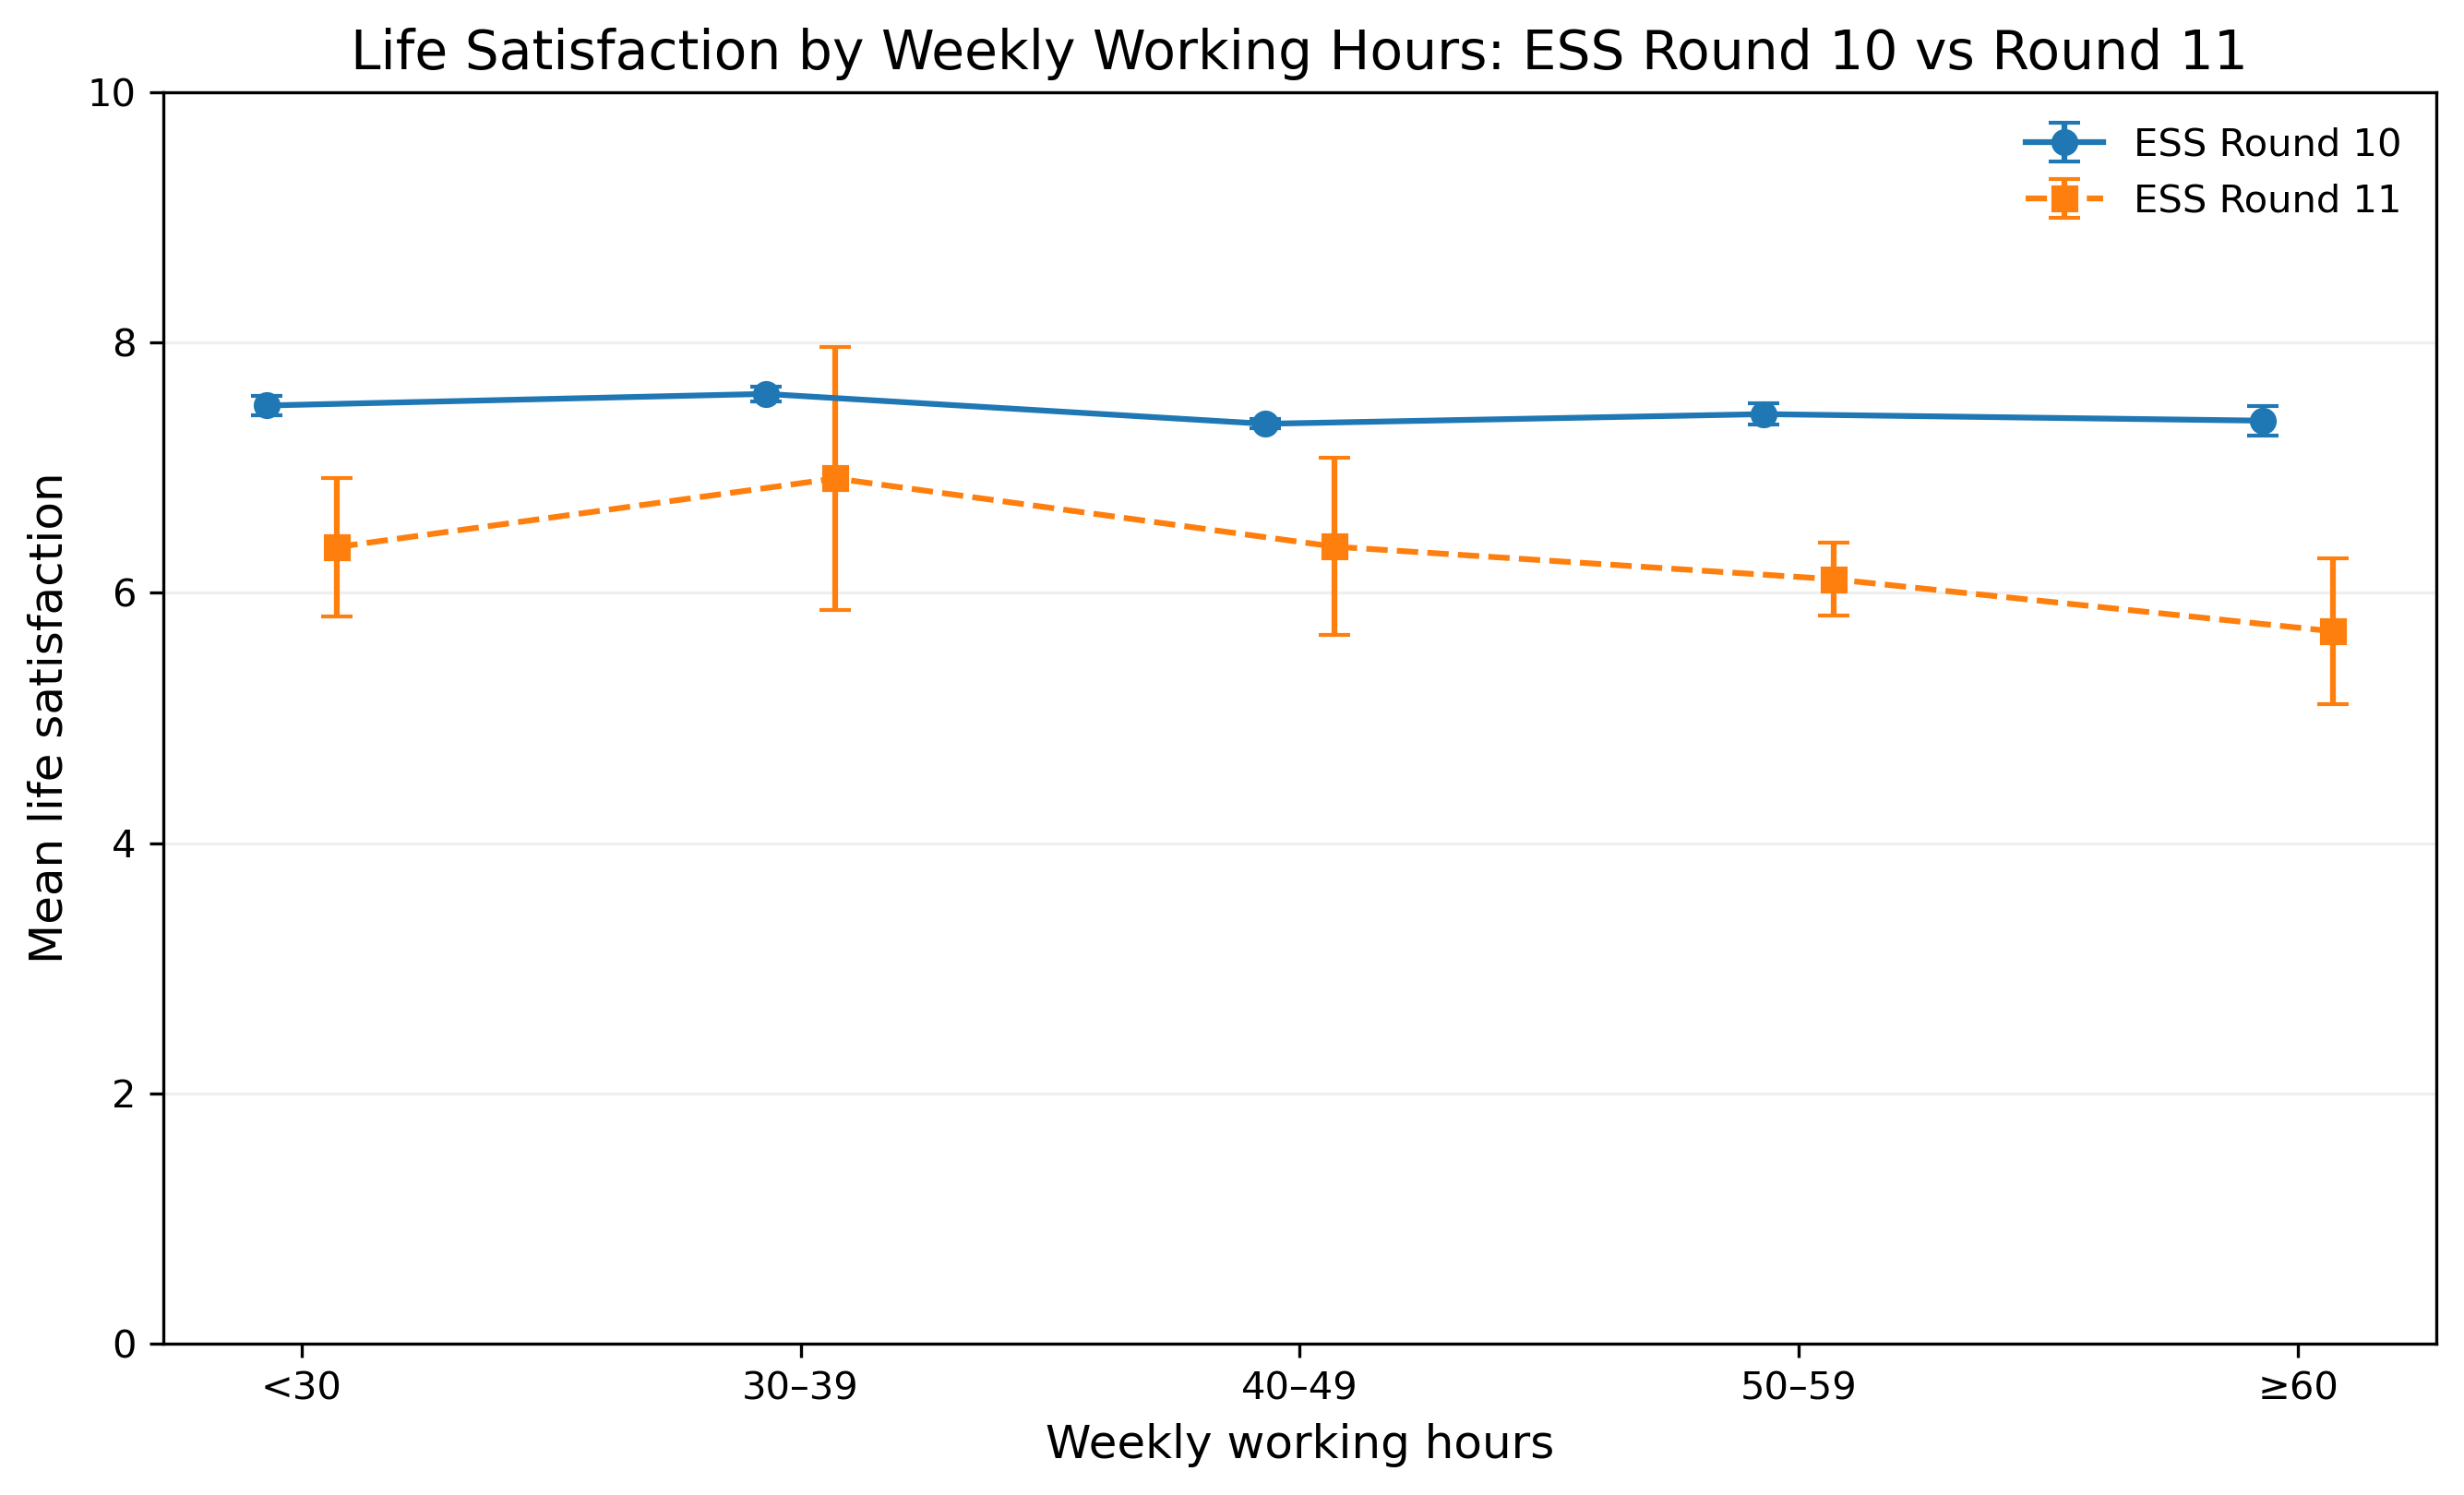

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. Read ESS10 and ESS11
# =========================

ess10_fig2 = pd.read_csv(
    "ESS10_worktime_lifesatisfaction_summary.csv"
)

ess11_fig2 = pd.read_csv(
    "ESS11_worktime_lifesatisfaction_summary.csv"
)

# Check
print("ESS10:")
display(ess10_fig2)

print("ESS11:")
display(ess11_fig2)


# =========================
# 2. Standardize group order
# =========================

group_order = ["<30", "30–39", "40–49", "50–59", "≥60"]

ess10_fig2["worktime_group"] = pd.Categorical(
    ess10_fig2["worktime_group"],
    categories=group_order,
    ordered=True
)

ess11_fig2["worktime_group"] = pd.Categorical(
    ess11_fig2["worktime_group"],
    categories=group_order,
    ordered=True
)

ess10_fig2 = ess10_fig2.sort_values("worktime_group")
ess11_fig2 = ess11_fig2.sort_values("worktime_group")


# =========================
# 3. Plot ESS10 vs ESS11
# =========================

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

x = np.arange(len(group_order))

# Slight horizontal offset so error bars do not overlap
offset = 0.07

# ESS10
ax.errorbar(
    x - offset,
    ess10_fig2["mean"],
    yerr=ess10_fig2["ci95"],
    fmt="o-",
    capsize=4,
    linewidth=1.5,
    markersize=6,
    label="ESS Round 10"
)

# ESS11
ax.errorbar(
    x + offset,
    ess11_fig2["mean"],
    yerr=ess11_fig2["ci95"],
    fmt="s--",
    capsize=4,
    linewidth=1.5,
    markersize=6,
    label="ESS Round 11"
)

ax.set_xticks(x)
ax.set_xticklabels(group_order)

ax.set_xlabel("Weekly working hours")
ax.set_ylabel("Mean life satisfaction")

ax.set_title(
    "Life Satisfaction by Weekly Working Hours: ESS Round 10 vs Round 11"
)

ax.legend(frameon=False)

ax.grid(axis="y", alpha=0.2)

# IMPORTANT:
# Don't use a very narrow y-axis until you have seen both datasets.
# Start with this and adjust later if needed.
ax.set_ylim(0, 10)

plt.tight_layout()

# =========================
# 4. Save
# =========================

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

plt.savefig(
    output_dir / "Figure_ESS10_vs_ESS11_LifeSatisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [141]:
plt.savefig(
    output_dir / "Figure2_ESS10_vs_ESS11_LifeSatisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 2400x1500 with 0 Axes>

In [142]:
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_ylim(0, 10)

plt.tight_layout()

# Export Figure 2
plt.savefig(
    output_dir / "Figure2_ESS10_vs_ESS11_LifeSatisfaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 2400x1500 with 0 Axes>

In [143]:
coef_table

,variable,coef,lower,upper,pvalue,label
1,worktime,-0.003976,-0.005693,-0.002259,5.681018e-06,Weekly working hours
3,age,0.011823,0.009982,0.013664,3.475992e-36,Age
2,gender,-0.107027,-0.159246,-0.054809,5.907478e-05,Gender
6,education,-0.021188,-0.053001,0.010626,1.917667e-01,Education
7,income,0.093866,0.083071,0.104661,1.198433e-64,Income
4,married,0.222012,0.167103,0.276922,2.406718e-15,Marital status
5,religion,-0.073085,-0.124717,-0.021452,5.535043e-03,Religion
8,health_clean,0.494613,0.462034,0.527192,3.666142e-190,Health
9,social_inclusion,0.177766,0.149120,0.206411,6.508577e-34,Social inclusion
10,digitalization,0.000116,-0.000028,0.000259,1.146711e-01,Digitalization


In [144]:
coef_table.to_csv(
    "ESS10_OLS_coefficients.csv",
    index=False
)

print("ESS10 OLS coefficients exported.")

ESS10 OLS coefficients exported.


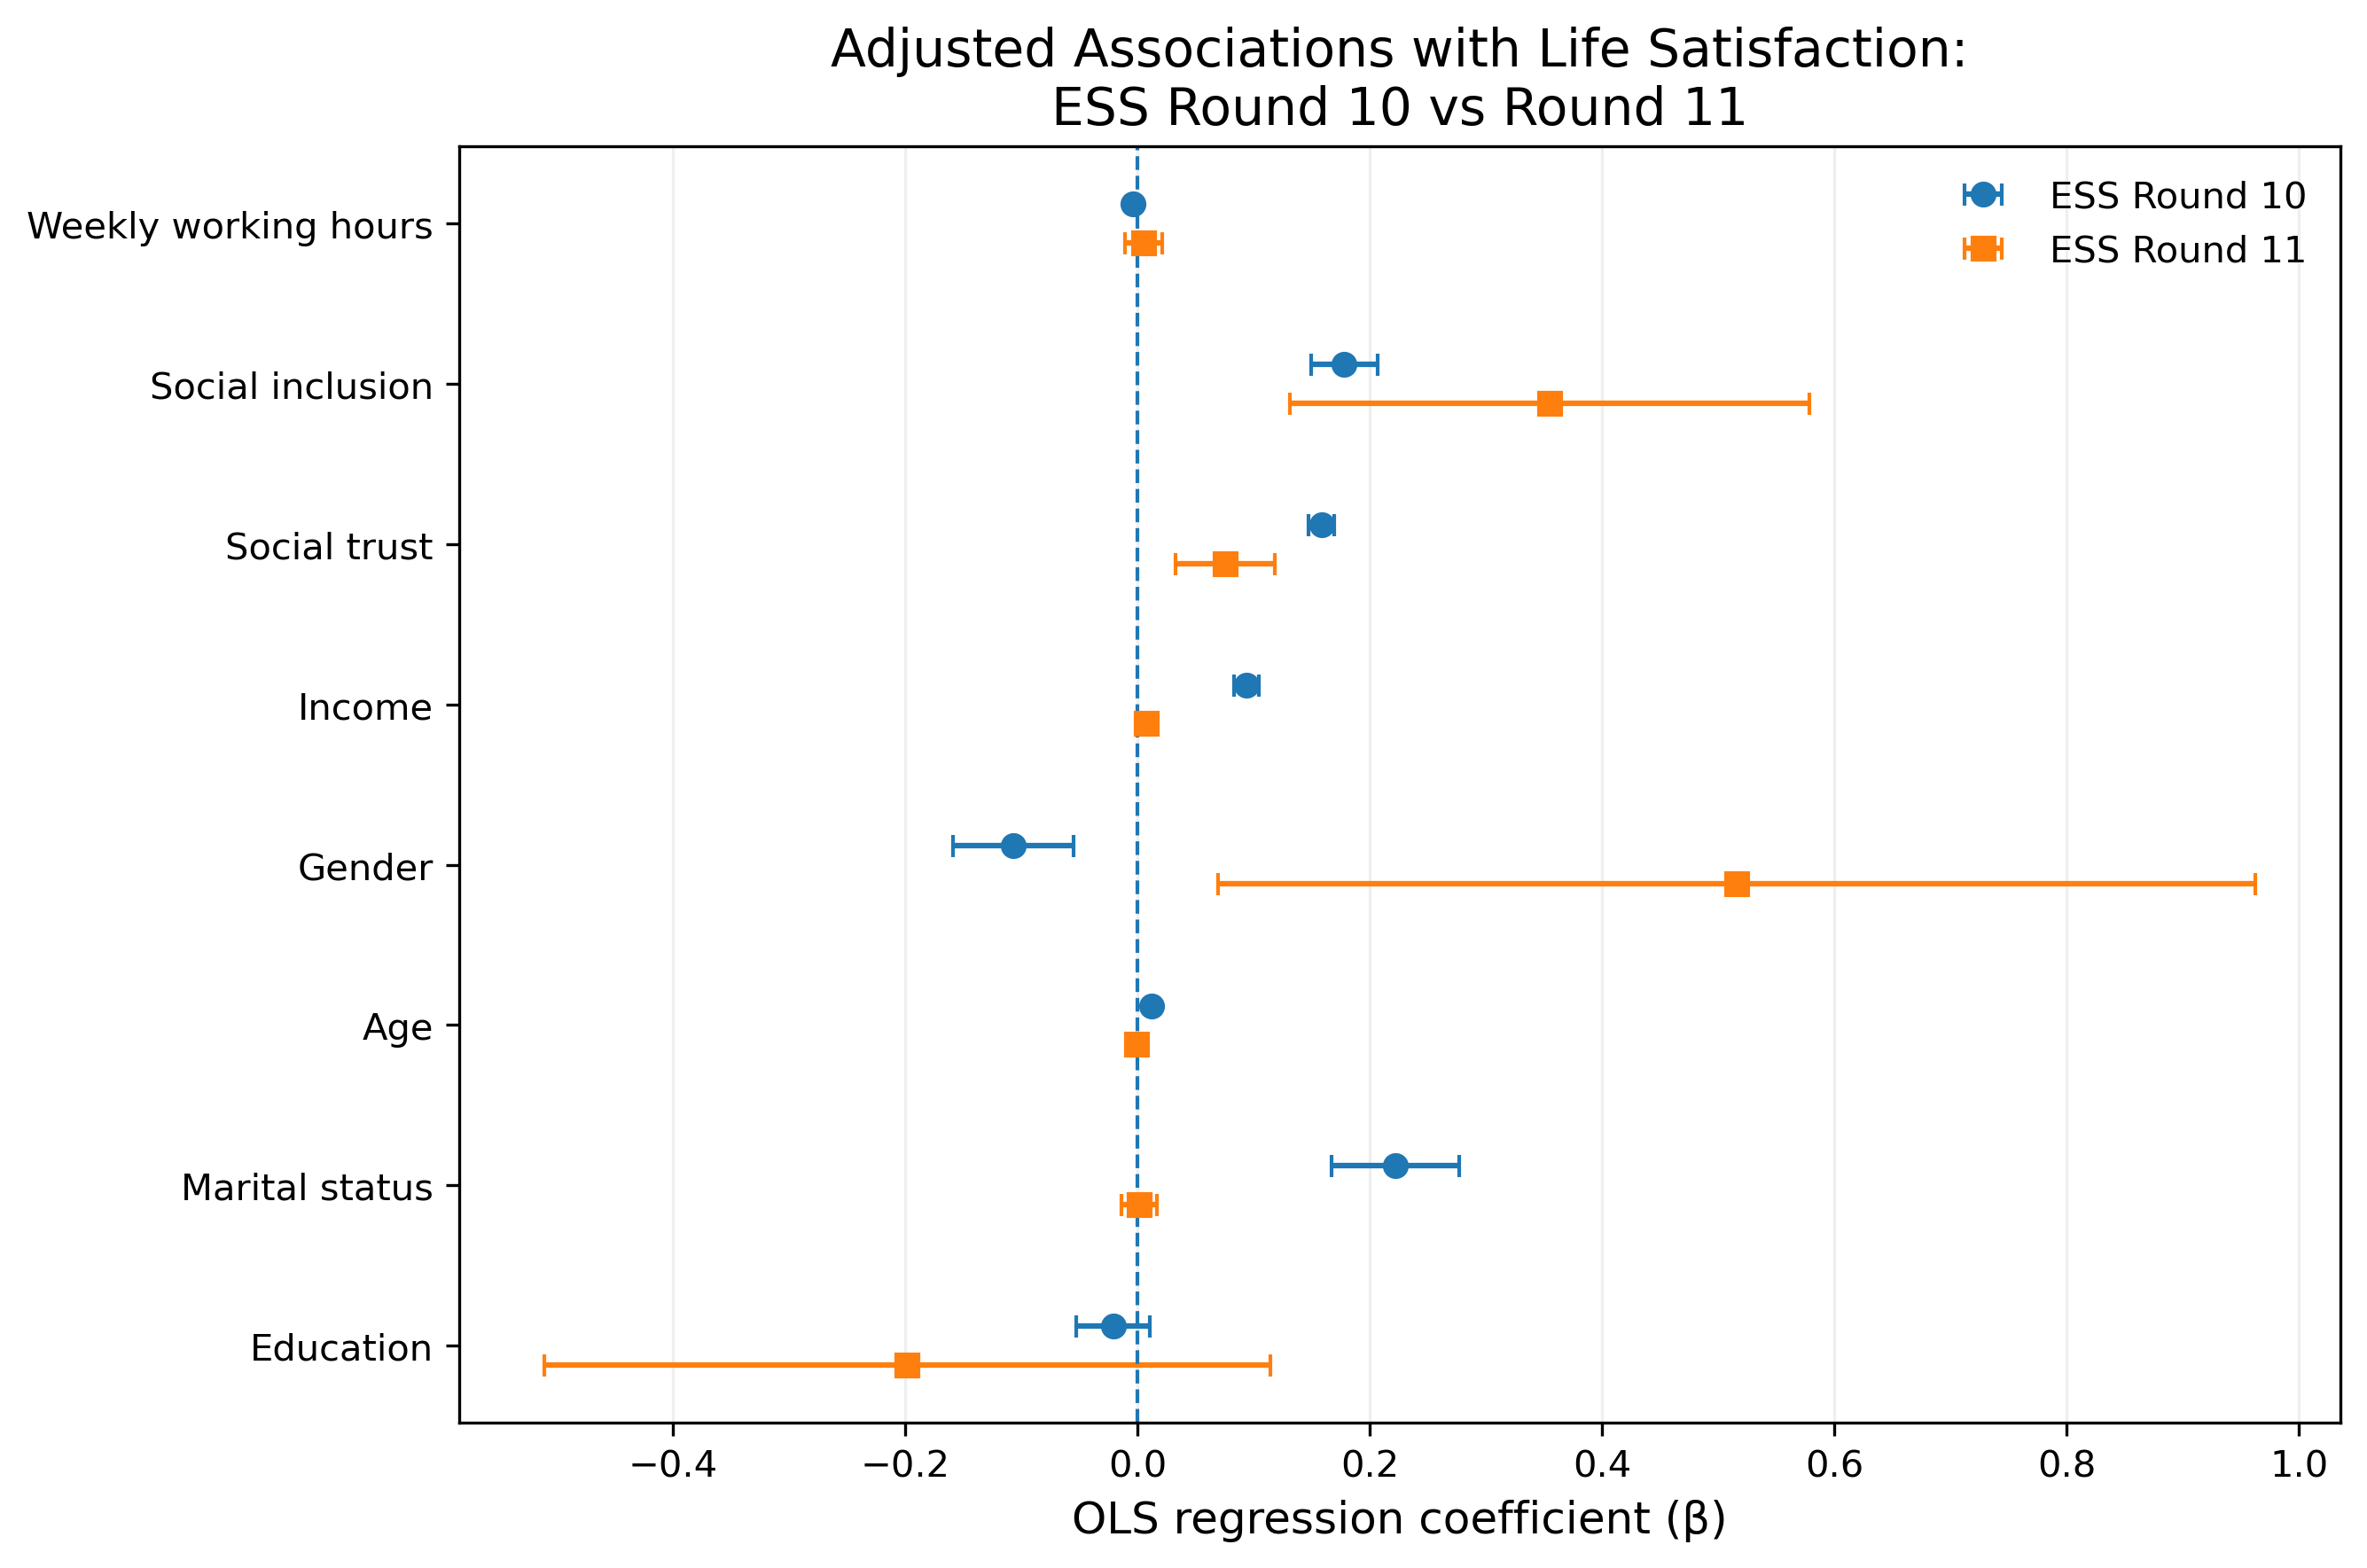

Saved to: C:\Users\20496\Desktop\ESS10_analysis\outputs\Figure3_ESS10_vs_ESS11_OLS_forest.png


In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# Figure 3: ESS10 vs ESS11 OLS coefficient comparison
# =========================================================

# ---------- ESS Round 10 ----------
ess10_coef = pd.DataFrame({
    "variable": [
        "Weekly working hours",
        "Social inclusion",
        "Social trust",
        "Income",
        "Gender",
        "Age",
        "Marital status",
        "Education"
    ],
    "coef": [
        -0.003976,
         0.177766,
         0.158199,
         0.093866,
        -0.107027,
         0.011823,
         0.222012,
        -0.021188
    ],
    "lower": [
        -0.005693,
         0.149120,
         0.147300,
         0.083071,
        -0.159246,
         0.009982,
         0.167103,
        -0.053001
    ],
    "upper": [
        -0.002259,
         0.206411,
         0.169097,
         0.104661,
        -0.054809,
         0.013664,
         0.276922,
         0.010626
    ]
})

# ---------- ESS Round 11 ----------
ess11_coef = pd.DataFrame({
    "variable": [
        "Weekly working hours",
        "Social inclusion",
        "Social trust",
        "Income",
        "Gender",
        "Age",
        "Marital status",
        "Education"
    ],
    "coef": [
         0.005355,
         0.354586,
         0.075235,
         0.007299,
         0.515623,
        -0.000961,
         0.001505,
        -0.198353
    ],
    "lower": [
        -0.010736,
         0.130965,
         0.032427,
         0.000572,
         0.069171,
        -0.003289,
        -0.013695,
        -0.510632
    ],
    "upper": [
         0.021445,
         0.578207,
         0.118044,
         0.014025,
         0.962074,
         0.001367,
         0.016706,
         0.113926
    ]
})

# ---------- Plot ----------
variables = ess10_coef["variable"].tolist()
y = np.arange(len(variables))

fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# ESS10
ax.errorbar(
    ess10_coef["coef"],
    y - 0.12,
    xerr=[
        ess10_coef["coef"] - ess10_coef["lower"],
        ess10_coef["upper"] - ess10_coef["coef"]
    ],
    fmt="o",
    capsize=3,
    label="ESS Round 10"
)

# ESS11
ax.errorbar(
    ess11_coef["coef"],
    y + 0.12,
    xerr=[
        ess11_coef["coef"] - ess11_coef["lower"],
        ess11_coef["upper"] - ess11_coef["coef"]
    ],
    fmt="s",
    capsize=3,
    label="ESS Round 11"
)

# Zero reference line
ax.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)

# Labels
ax.set_yticks(y)
ax.set_yticklabels(variables)
ax.invert_yaxis()

ax.set_xlabel("OLS regression coefficient (β)")
ax.set_ylabel("")
ax.set_title(
    "Adjusted Associations with Life Satisfaction:\n"
    "ESS Round 10 vs Round 11"
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()


# =========================================================
# SAVE FIGURE 3
# =========================================================

fig.savefig(
    output_dir / "Figure3_ESS10_vs_ESS11_OLS_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved to:",
    (output_dir / "Figure3_ESS10_vs_ESS11_OLS_forest.png").resolve()
)

In [148]:
plt.tight_layout()

plt.savefig(
    output_dir / "Figure3_ESS10_vs_ESS11_OLS_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 2400x1500 with 0 Axes>